# Cloud Building Blocks Compared: Which Service for Which Job on AWS, Google Cloud and Azure

> **Who is this for:** anyone who has an AI application (a model API, a RAG chat app, an agent, a batch scoring job) working on a laptop and now has to pick cloud services to run it. You may know one cloud a little, or none. This notebook is a **chooser**: for each job, it shows the matching service on AWS, Google Cloud and Azure, and when to pick which.
>
> **What you will learn:**
> - **Compute:** bare VMs vs managed containers vs Kubernetes vs serverless functions vs managed model endpoints, on all three clouds. Who manages what, how each one scales, how it is billed, cold starts, GPUs and limits. A decision flowchart, a runnable chooser, a cold-start simulation and cost-shape curves.
> - **Databases and storage:** relational, key-value, document, graph, wide-column, time-series, cache, search/vector, warehouse, object, block and file storage. Which one fits users and billing, chat history, embeddings, caching, logs and files. A runnable "pick a database" chooser and a replica-lag demo.
> - **Messaging and events:** queue vs topic vs stream vs workflow (SQS, SNS, EventBridge, Kinesis, MSK, Amazon MQ, Step Functions; Pub/Sub, Cloud Tasks, Eventarc, Workflows; Service Bus, Event Grid, Event Hubs, Storage Queues, Logic Apps, Durable Functions), with a runnable mini simulation of each delivery model.
> - **Email, SMS and notifications:** Amazon SES, AWS End User Messaging and the Amazon Pinpoint end of support, Azure Communication Services, what to do on Google Cloud, third-party providers, SPF/DKIM/DMARC and deliverability. A runnable email-sending wrapper (templates, suppression list, rate limiting, retries) and a DNS record checker.
> - **The rest of the front door:** VPC/VNet, load balancers, CDN, DNS, API gateways, app-user identity vs workforce IAM, secrets, monitoring, CI/CD and infrastructure as code.
> - A **"same need, three clouds" master table** (40+ rows) saved as a CSV, common beginner mistakes, "start simple" plans for a small and a large AI SaaS, a recap, interview questions and official comparison pages.
>
> **Prerequisites:** basic Python. It helps (but is not required) to have skimmed one cloud notebook. This notebook stays at the "which one and why" level and links to the deep dives:
> - AWS: [06 AWS core services](./06_aws_core_services_for_ai_engineers.ipynb), [07 SageMaker AI, Bedrock, AgentCore](./07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb)
> - Azure: [08 Azure core services](./08_azure_core_services_for_ai_engineers.ipynb), [09 Microsoft Foundry and Azure OpenAI](./09_azure_ai_microsoft_foundry_and_azure_openai.ipynb)
> - Google Cloud: [10 Google Cloud core services](./10_gcp_core_services_for_ai_engineers.ipynb), [11 Gemini Enterprise Agent Platform](./11_gcp_ai_gemini_enterprise_agent_platform.ipynb)
> - Kubernetes: [02 Kubernetes deep dive for AI workloads](../17_Docker/kubernetes/02_kubernetes_deep_dive_for_ai_workloads.ipynb), [03 GPU infrastructure and LLM serving on Kubernetes](../17_Docker/kubernetes/03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb)
> - Serverless and queues: [16_Deployment/03 serverless deployment](../16_Deployment/03_serverless_deployment.ipynb), [message queues](../16_Deployment/message_queues/01_message_queues.ipynb)
> - Cost: [04 cloud cost optimization](./04_cloud_cost_optimization.ipynb); vector stores: [vector databases](../13_Databases/03_vector_db/01_vector_databases.ipynb)
>
> **Time needed:** about 90 minutes to read and run.
>
> **Runs on:** CPU only. No cloud account, no API key, no internet. Every cloud command is shown as text only. All prices in this notebook are **made-up example numbers**, used only to show the *shape* of a cost curve.
>
> **Names are as of late 2026.** Cloud products get renamed and retired often. Where a name changed recently, the old name is given once in brackets.

## Table of contents

0. Setup
1. The one big idea: who manages what
2. Compute: where your code runs
3. Databases and storage: where your data lives
4. Messaging and events: how parts talk to each other
5. Email, SMS and notifications: how you reach users
6. Networking, edge, identity, secrets, monitoring, CI/CD and IaC
7. The master table: same need, three clouds (and a CSV)
8. Common beginner mistakes, by area
9. Start simple: a small AI SaaS vs a large one
10. How to try it for real (free tiers and local emulators)
11. Certification topic map
12. Recap / cheat sheet
13. Interview questions
14. Further reading

## 0. Setup

Only the Python standard library plus numpy, pandas and matplotlib. A fixed random seed makes every simulation print the same result each run.

In [1]:
import os, re, math, random, string, tempfile, heapq, time
from collections import deque, defaultdict
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 80)

def show(df, n=None):
    """Print a DataFrame as plain text (easy to read in any viewer)."""
    print((df if n is None else df.head(n)).to_string(index=False))

print("ready")

ready


## 1. The one big idea: who manages what

**What it is.** Every cloud service sits somewhere on a line. At one end you get a bare computer and do everything yourself. At the other end you hand over a piece of code (or just call an API) and the cloud does everything else. Moving along the line, you give up control and get less work in return.

**Simple analogy: places to live.**

| Option | Housing analogy | Cloud example | What you still do |
|---|---|---|---|
| Your own data center | Own a house | On-premises servers | Everything, including the roof |
| Virtual machine (VM) | Rent an empty flat | EC2, Compute Engine, Azure VMs | Furniture, cleaning, repairs inside (OS patches, runtime, scaling) |
| Managed containers | Serviced apartment | ECS on Fargate, Cloud Run, Azure Container Apps | Bring your suitcase (the container image) and say how many rooms you need |
| Managed Kubernetes | Run a small hotel in a building someone else maintains | EKS, GKE, AKS | Run the hotel: staff, rooms, rules (cluster add-ons, upgrades, node pools) |
| Serverless functions | Hotel room by the night | Lambda, Cloud Run functions, Azure Functions | Just show up (your function code); pay only for the nights you stay |
| Managed model endpoint / model API | Room service | SageMaker AI endpoints, Agent Platform endpoints, Azure ML / Foundry endpoints, Bedrock | Order the dish (the model); someone else cooks |

**A few words used everywhere in this notebook** (one line each):
- **Managed service:** the cloud runs and patches the servers behind the service for you.
- **Serverless:** you never see or size servers; the service adds and removes capacity for you and usually bills per request or per second of use.
- **Scale to zero:** when nobody is calling, nothing is running and (usually) you pay nothing for compute.
- **Cold start:** the extra wait for the first request after scale to zero, while the platform starts a fresh copy of your code.
- **Control plane / data plane:** the control plane is the "management API" (create, configure); the data plane does the real work (serve requests, store rows).
- **Region / zone:** a region is a geographic area (for example, a city); a zone is one data center (or group of them) inside it. Spreading over zones protects you from one building failing.

**The trade-off in one sentence:** the more the cloud manages, the faster you ship and the fewer things you can break, but the less you can tune, and the more the price depends on *how* you use it (always-on vs per request).

In [2]:
# The shared responsibility idea as a table: who does each job?
jobs = ["Physical hardware", "Host OS / hypervisor", "Guest OS patches", "Language runtime",
        "Scaling (add/remove copies)", "Load balancing", "Your code and data", "Access rules (IAM)"]
levels = {
    "VM (EC2 / Compute Engine / Azure VM)":       ["Cloud", "Cloud", "You", "You", "You (or autoscaling group)", "You (add a load balancer)", "You", "You"],
    "Managed containers (Fargate / Cloud Run / Container Apps)": ["Cloud", "Cloud", "Cloud", "You (in image)", "Cloud (you set rules)", "Cloud", "You", "You"],
    "Kubernetes (EKS / GKE / AKS)":               ["Cloud", "Cloud", "Shared (node images)", "You (in image)", "Shared (HPA + node autoscaler)", "Shared (Service / Gateway)", "You", "You"],
    "Functions (Lambda / Cloud Run functions / Azure Functions)": ["Cloud", "Cloud", "Cloud", "Cloud (managed runtime)", "Cloud", "Cloud", "You", "You"],
    "Model endpoint (SageMaker AI / Agent Platform / Azure ML)":   ["Cloud", "Cloud", "Cloud", "Cloud (serving container)", "Cloud (you set rules)", "Cloud", "You (model + data)", "You"],
}
resp = pd.DataFrame(levels, index=jobs).T
resp.index.name = "Service style"
print(resp.to_string())
print("\nNote: 'Your code and data' and 'Access rules' are ALWAYS your job, on every cloud and every service.")

                                                           Physical hardware Host OS / hypervisor      Guest OS patches           Language runtime     Scaling (add/remove copies)              Load balancing  Your code and data Access rules (IAM)
Service style                                                                                                                                                                                                                                        
VM (EC2 / Compute Engine / Azure VM)                                   Cloud                Cloud                   You                        You      You (or autoscaling group)   You (add a load balancer)                 You                You
Managed containers (Fargate / Cloud Run / Container Apps)              Cloud                Cloud                 Cloud             You (in image)           Cloud (you set rules)                       Cloud                 You                You
Kubernetes (EKS 

## 2. Compute: where your code runs

This section has four parts:
1. The AWS options one by one (AWS has the most of them, so it is a good map).
2. The Google Cloud and Azure equivalents.
3. A decision flowchart and a runnable chooser.
4. Cold starts and cost shapes, with a simulation and a plot.

Deep dives already in the repo: AWS compute in [06, section 5](./06_aws_core_services_for_ai_engineers.ipynb), Google Cloud compute in [10, section 5](./10_gcp_core_services_for_ai_engineers.ipynb), Azure compute in [08, section 8](./08_azure_core_services_for_ai_engineers.ipynb), Kubernetes in [17_Docker/kubernetes/02](../17_Docker/kubernetes/02_kubernetes_deep_dive_for_ai_workloads.ipynb).

### 2.1 AWS compute, one service at a time

**Amazon EC2 (Elastic Compute Cloud)**
- **What it is:** a virtual machine you rent by the second. You choose the size (CPU, memory, GPU) and the operating system image.
- **Analogy:** renting an empty flat. Full freedom, full chores.
- **How it scales:** by hand, or with an **Auto Scaling group** (a rule that keeps N copies running and adds more when CPU or queue depth is high).
- **Pricing shape:** pay for every hour it is on, busy or idle. Cheaper with Savings Plans / Reserved Instances (commit for 1-3 years) or **Spot** (spare capacity at a big discount, can be taken back with a 2-minute warning).
- **GPUs:** yes, the widest choice (NVIDIA G and P families, AWS Trainium and Inferentia chips).
- **Use it for AI when:** you need a specific GPU, a custom driver, long training runs, or a self-hosted model server (vLLM, Triton) and you are fine running the OS.

**Amazon ECS (Elastic Container Service)**
- **What it is:** AWS's own container orchestrator. You describe a *task* (one or more containers) and a *service* (keep N tasks running behind a load balancer). ECS needs somewhere to run the tasks, called a *capacity provider*:
  - **ECS on EC2:** tasks run on EC2 instances that you own and patch. Supports GPUs. Cheapest at high, steady use.
  - **ECS on Fargate:** tasks run on AWS-managed capacity; there are no servers to see. You pay per vCPU-second and GB-second while the task runs. **No GPUs on Fargate.**
  - **ECS Managed Instances:** a middle option. AWS picks, patches and replaces the EC2 instances for you, and you still get EC2 choices such as GPU instance types (NVIDIA drivers come preinstalled).
- **Analogy:** a serviced apartment block. With Fargate you never see the building; with EC2 you also run the building.
- **Use it for AI when:** you have a containerised API (FastAPI, a RAG backend, a small model) and do not want Kubernetes.

**Amazon ECS Express Mode** (the recommended path for people who used **AWS App Runner**)
- **What it is:** one API call (`create-express-gateway-service`) or a console wizard. You give a container image and two IAM roles; ECS creates an ECS service on Fargate, an Application Load Balancer, HTTPS, autoscaling and networking, and returns a URL. There is no extra charge; you pay for the resources it creates.
- **App Runner status (late 2026):** App Runner is **closed to new customers** (from 30 April 2026). Existing customers can keep using it, but no new features are planned. New projects should start on ECS Express Mode.
- **Analogy:** a "move-in ready" serviced apartment: one form and the keys are yours.
- **Use it for AI when:** you want the fastest path from "I have a Docker image" to "I have an HTTPS URL" on AWS.

**Amazon EKS (Elastic Kubernetes Service)**
- **What it is:** managed Kubernetes. AWS runs the Kubernetes control plane; you run workloads on node groups, Fargate, or **EKS Auto Mode** (AWS also manages the nodes, scaling and core add-ons).
- **Analogy:** a hotel in a building someone else maintains. Very flexible, but you are running a hotel.
- **Use it for AI when:** you already use Kubernetes, need GPU scheduling across many models, or want portable tooling (Helm, KServe, vLLM, Ray). See [17_Docker/kubernetes/03](../17_Docker/kubernetes/03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).
- **When not:** a team of one or two with one API. The cluster itself is a product you have to look after.

**AWS Fargate** is not a separate place to deploy; it is the serverless capacity used *by* ECS (and, for some pods, EKS). People say "Fargate" when they mean "ECS on Fargate".

**AWS Lambda**
- **What it is:** serverless functions. You upload code; Lambda runs it when an event arrives (an HTTP call, a file in S3, a message in a queue) and bills per request plus per millisecond of run time. As of late 2026 the Lambda docs describe three "compute primitives":
  - **Event Functions** (the classic Lambda function): up to **15 minutes** per invocation, 128 MB to 10,240 MB memory (CPU grows with memory), 6 MB request/response for synchronous calls (larger with response streaming), up to a 10 GB container image. **Durable functions** let a multi-step workflow checkpoint and wait (up to a year) without paying while it waits. **Lambda Managed Instances** run functions on EC2 instances you choose, managed by Lambda.
  - **Web Functions:** run a normal web server (Node.js frameworks) with many concurrent requests per environment, scale to zero, HTTPS endpoint included.
  - **MicroVMs:** an isolated, long-lived (up to 8 hours) environment per user or job, with suspend and resume. Aimed at running untrusted or AI-generated code.
- **Analogy:** a hotel room by the night. You only pay while you are in it.
- **GPUs:** no GPU option for Lambda functions.
- **Use it for AI when:** glue code, webhooks, light pre/post-processing, calling a model API (Bedrock or another provider), reacting to uploads, small CPU models.
- **When not:** big models (package size and memory limits, no GPU), jobs over 15 minutes (unless durable functions or Managed Instances fit), very steady high traffic (always-on is cheaper).

**AWS Elastic Beanstalk**
- **What it is:** an older "platform as a service". You upload code (Python, Node.js, Java, .NET, Docker) and Beanstalk creates EC2 instances, a load balancer and autoscaling for you. It is still active in 2026 (new features include a GitHub deploy action, AI-powered environment health analysis, and a "Cluster Mode" built on EKS for running several apps on shared infrastructure).
- **Analogy:** a furnished flat that comes with a building manager.
- **Use it for AI when:** a classic web app team wants EC2 under the hood without wiring it all up. For new container-first projects, ECS Express Mode is usually simpler.

**Amazon Lightsail**
- **What it is:** simple virtual private servers, container services, managed MySQL/PostgreSQL, a CDN and a load balancer, all for a **fixed monthly bundle price**.
- **Analogy:** a phone plan: a known monthly bill with an allowance.
- **Use it for AI when:** a demo, a hobby project, or a small website that calls a model API. **Not** for GPUs or big scale; you can peer it with a normal VPC later.

**AWS Batch**
- **What it is:** a managed job queue for batch work. You submit jobs; Batch starts EC2 (including GPU and Spot) or Fargate capacity, runs the jobs and shuts capacity down.
- **Analogy:** a print shop queue: drop off jobs, collect results later.
- **Use it for AI when:** nightly embedding of documents, offline scoring, data preparation, hyperparameter sweeps.

**Amazon SageMaker AI endpoints** (SageMaker was renamed **SageMaker AI** in Dec 2024)
- **What it is:** managed model hosting. Four inference options: **real-time** (always-on, low latency, GPUs), **serverless** (scale to zero, CPU only, small payloads), **asynchronous** (queue in front, large payloads, long requests, can scale to zero) and **batch transform** (offline over a dataset). Details in [07](./07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb).
- **Analogy:** room service for models.
- **Use it for AI when:** you host your own trained or open-weights model and want autoscaling, model monitoring and A/B variants without building them.
- If you only need a hosted foundation model by API, **Amazon Bedrock** (or Bedrock AgentCore for agents) means you host nothing at all.

In [3]:
# The AWS compute options side by side. Numbers are the main documented limits (late 2026);
# always check the current quotas page before you design around a number.
aws_compute = pd.DataFrame([
    ["EC2",                    "VM",                     "You (or ASG rules)",       "Per second while on",           "None (always on)",       "Yes (widest)",        "None really; you size it",           "Custom GPU serving, training, anything"],
    ["ECS on EC2",             "Containers on your VMs", "Service autoscaling + ASG","Per instance-hour",             "None if tasks kept warm","Yes",                 "You manage instances",               "Steady container APIs, GPU containers"],
    ["ECS on Fargate",         "Serverless containers",  "Service autoscaling",      "Per vCPU-s and GB-s per task",  "Task start ~tens of s",  "No",                  "No GPU; size caps per task",         "CPU APIs, RAG backends, workers"],
    ["ECS Managed Instances",  "Containers, AWS-run VMs","Managed by ECS",            "Instance cost + mgmt fee",      "Instance launch if 0",   "Yes",                 "Newer option (2025+)",               "GPU containers without node chores"],
    ["ECS Express Mode",       "One-call container app", "Autoscaling built in",     "Underlying Fargate + ALB",      "Like Fargate",           "No (Fargate)",        "Opinionated defaults",               "Fastest HTTPS URL for a container"],
    ["App Runner (closed)",    "Container PaaS",         "Built in",                 "Per vCPU/GB active",            "Low",                    "No",                  "Closed to new customers (Apr 2026)", "Existing users only"],
    ["EKS (+ Auto Mode)",      "Managed Kubernetes",     "HPA + Karpenter/Auto Mode","Cluster fee + nodes",           "Pod start; node launch", "Yes",                 "You run the cluster",                "Many models, GPU pools, portability"],
    ["Lambda Event Functions", "Functions",              "Automatic per request",    "Per request + GB-ms",           "Yes (100s ms to s)",     "No",                  "15 min, 10 GB mem, 6 MB sync payload","Glue, webhooks, calling model APIs"],
    ["Lambda Web Functions",   "Serverless web server",  "Automatic, scale to 0",    "Per request + active CPU + mem","Yes",                    "No",                  "Node.js runtimes; 2 vCPU/env",       "Small web/API backends"],
    ["Lambda MicroVMs",        "Per-user isolated VM",   "You create/suspend/resume","Per second running",            "Near-instant resume",    "No",                  "Up to 8 h per MicroVM",              "Sandboxes for AI-generated code"],
    ["Elastic Beanstalk",      "PaaS on EC2",            "ASG managed for you",      "Underlying EC2 + ALB",          "None (always on)",       "Via EC2 types",       "Older model; less flexible",         "Classic web apps on EC2"],
    ["Lightsail",              "Simple VPS bundles",     "Manual",                   "Fixed monthly bundle",          "None",                   "No",                  "Small sizes; simple networking",     "Demos, hobby apps calling APIs"],
    ["AWS Batch",              "Batch job queue",        "Scales capacity per queue","Underlying EC2/Fargate",        "Minutes (capacity)",     "Yes (EC2)",           "Not for request/response",           "Embedding jobs, offline scoring"],
    ["SageMaker AI endpoints", "Managed model hosting",  "Endpoint autoscaling",     "Per instance-hour or per use",  "Serverless/async: yes",  "Yes (real-time/async)","Serverless: CPU only, small payload","Hosting your own models"],
], columns=["Service", "What it is", "Scaling", "Pricing shape", "Cold start", "GPU", "Main limits", "Typical AI use"])
show(aws_compute)

               Service              What it is                   Scaling                  Pricing shape              Cold start                   GPU                          Main limits                         Typical AI use
                   EC2                      VM        You (or ASG rules)            Per second while on        None (always on)          Yes (widest)             None really; you size it Custom GPU serving, training, anything
            ECS on EC2  Containers on your VMs Service autoscaling + ASG              Per instance-hour None if tasks kept warm                   Yes                 You manage instances  Steady container APIs, GPU containers
        ECS on Fargate   Serverless containers       Service autoscaling   Per vCPU-s and GB-s per task   Task start ~tens of s                    No           No GPU; size caps per task        CPU APIs, RAG backends, workers
 ECS Managed Instances Containers, AWS-run VMs            Managed by ECS       Instance cost + m

### 2.2 Google Cloud and Azure equivalents

**Google Cloud** (deep dive: [10, section 5](./10_gcp_core_services_for_ai_engineers.ipynb))
- **Compute Engine:** VMs, including GPU VMs and TPU VMs. **Managed instance groups (MIGs)** are the autoscaling group.
- **GKE (Google Kubernetes Engine):** managed Kubernetes in two modes. **Standard**: you manage node pools. **Autopilot**: Google manages nodes and you pay per pod resources. GKE has strong AI features (GPU and TPU node pools, GKE Inference Gateway).
- **Cloud Run:** serverless containers, and the closest thing to "ECS Express Mode + Fargate + Lambda" in one product. **Services** (HTTP, scale to zero, request-based or instance-based billing), **jobs** (run to completion, array jobs), **worker pools** (always-on non-HTTP workers such as queue consumers) and **Cloud Run functions** (formerly Cloud Functions: you deploy just a function). Cloud Run services and jobs can attach **GPUs** (NVIDIA L4 and RTX PRO 6000 Blackwell as of late 2026), and GPU services can scale to zero.
- **App Engine:** the original Google PaaS. Still runs, but treat it as **legacy**; new apps go to Cloud Run.
- **Batch:** managed batch jobs on Compute Engine (including GPUs and Spot VMs).
- **Agent Platform endpoints** (Gemini Enterprise Agent Platform, formerly **Vertex AI**): managed model hosting and online/batch inference. Hosted Gemini and partner models are called by API with nothing to host. Deep dive: [11](./11_gcp_ai_gemini_enterprise_agent_platform.ipynb).

**Azure** (deep dive: [08, section 8](./08_azure_core_services_for_ai_engineers.ipynb))
- **Virtual Machines** and **Virtual Machine Scale Sets (VMSS)**: VMs and their autoscaling group, including GPU sizes (NC, ND families).
- **AKS (Azure Kubernetes Service):** managed Kubernetes (with an "Automatic" option that manages more for you).
- **Azure Container Apps:** serverless containers built on Kubernetes and KEDA (event-driven autoscaling), with scale to zero, **jobs**, and **serverless GPUs**. The closest match to Cloud Run.
- **Azure Container Instances (ACI):** run a single container (or a small group) quickly, without orchestration. Good for one-off tasks; no autoscaling service model.
- **Azure App Service:** a mature PaaS for web apps and APIs (code or containers). The match for Elastic Beanstalk and Lightsail-style web hosting.
- **Azure Functions:** serverless functions. **Flex Consumption** is the recommended serverless plan as of late 2026; **Durable Functions** add stateful workflows.
- **Azure Batch:** managed batch pools of VMs.
- **Azure Machine Learning online/batch endpoints** and **Microsoft Foundry** (formerly Azure AI Foundry) for model deployments. Deep dive: [09](./09_azure_ai_microsoft_foundry_and_azure_openai.ipynb).

In [4]:
compute_map = pd.DataFrame([
    ["Rent a VM",                          "EC2",                                  "Compute Engine",                       "Virtual Machines"],
    ["Autoscaling group of VMs",           "EC2 Auto Scaling group",               "Managed instance group (MIG)",         "Virtual Machine Scale Sets"],
    ["Managed Kubernetes",                 "EKS (Auto Mode optional)",             "GKE Standard / Autopilot",             "AKS (Automatic optional)"],
    ["Serverless containers (HTTP)",       "ECS on Fargate / ECS Express Mode",    "Cloud Run services",                   "Azure Container Apps"],
    ["Run-to-completion container jobs",   "ECS tasks / AWS Batch on Fargate",     "Cloud Run jobs",                       "Container Apps jobs / ACI"],
    ["Always-on background workers",       "ECS service (no load balancer)",       "Cloud Run worker pools",               "Container Apps (min replicas >= 1)"],
    ["Serverless functions",               "Lambda",                               "Cloud Run functions",                  "Azure Functions (Flex Consumption)"],
    ["Code-based PaaS for web apps",       "Elastic Beanstalk",                    "App Engine (legacy) / Cloud Run source deploy", "App Service"],
    ["Simple fixed-price hosting",         "Lightsail",                            "(none exact; small Compute Engine VM)","App Service (Basic tiers)"],
    ["Batch job service",                  "AWS Batch",                            "Batch",                                "Azure Batch"],
    ["Stateful function workflows",        "Lambda durable functions / Step Functions", "Workflows",                       "Durable Functions"],
    ["Host your own model as an endpoint", "SageMaker AI endpoints",               "Agent Platform endpoints",             "Azure ML online endpoints / Foundry managed compute"],
    ["Call a hosted foundation model",     "Amazon Bedrock",                       "Agent Platform (Gemini, Model Garden)","Foundry Models (incl. Azure OpenAI)"],
    ["Serverless GPU containers",          "(no Fargate GPU; use ECS Managed Instances / EKS / SageMaker AI)", "Cloud Run with GPU", "Container Apps serverless GPUs"],
], columns=["Need", "AWS", "Google Cloud", "Azure"])
show(compute_map)

                              Need                                                              AWS                                  Google Cloud                                               Azure
                         Rent a VM                                                              EC2                                Compute Engine                                    Virtual Machines
          Autoscaling group of VMs                                           EC2 Auto Scaling group                  Managed instance group (MIG)                          Virtual Machine Scale Sets
                Managed Kubernetes                                         EKS (Auto Mode optional)                      GKE Standard / Autopilot                            AKS (Automatic optional)
      Serverless containers (HTTP)                                ECS on Fargate / ECS Express Mode                            Cloud Run services                                Azure Container Apps
  Run-to-c

### 2.3 Decision flowchart

Read it top to bottom. The first "yes" usually gives a good default. It is a starting point, not a law.

```mermaid
flowchart TD
    A[New AI workload] --> B{Only calling a hosted model API?}
    B -- yes --> B1[Small container or function that calls Bedrock / Agent Platform / Foundry]
    B -- no --> C{Runs to completion, not request/response?}
    C -- yes --> C1{Needs GPU or runs for hours?}
    C1 -- yes --> C2[Batch service: AWS Batch / Google Batch / Azure Batch, or Cloud Run jobs with GPU]
    C1 -- no --> C3[Container jobs: ECS task / Cloud Run jobs / Container Apps jobs]
    C -- no --> D{Needs a GPU to serve?}
    D -- yes --> D1{Want the cloud to host the model?}
    D1 -- yes --> D2[Managed endpoint: SageMaker AI / Agent Platform / Azure ML or Foundry]
    D1 -- no --> D3{Team already runs Kubernetes?}
    D3 -- yes --> D4[EKS / GKE / AKS with GPU node pools]
    D3 -- no --> D5[Cloud Run GPU / Container Apps GPU / ECS Managed Instances]
    D -- no --> E{Short event-driven glue, under 15 min?}
    E -- yes --> E1[Functions: Lambda / Cloud Run functions / Azure Functions]
    E -- no --> F{Many services and a platform team?}
    F -- yes --> F1[Kubernetes: EKS / GKE / AKS]
    F -- no --> F2[Serverless containers: ECS Express Mode / Cloud Run / Container Apps]
```

### 2.4 Runnable: a compute chooser

**What it is:** a plain Python function that turns a few yes/no traits into a recommendation on each cloud, plus the reason. It encodes the flowchart above, so you can test edge cases quickly.

**How it works:** the traits are checked in priority order (hosted model API, batch, GPU, short events, platform team). The first rule that matches wins.

In [5]:
@dataclass
class Workload:
    name: str
    calls_hosted_model_only: bool = False   # just calls Bedrock / Gemini / Azure OpenAI etc.
    batch: bool = False                     # runs to completion (not request/response)
    needs_gpu: bool = False
    max_minutes: float = 1.0                # longest single unit of work
    spiky_or_idle: bool = True              # long quiet periods between bursts?
    has_k8s_team: bool = False
    many_services: bool = False
    wants_managed_model_hosting: bool = False

def choose_compute(w: Workload):
    """Return (style, AWS, Google Cloud, Azure, reason). Rules are checked in order."""
    if w.calls_hosted_model_only:
        if w.max_minutes <= 15 and w.spiky_or_idle:
            return ("functions", "Lambda", "Cloud Run functions", "Azure Functions",
                    "Thin glue around a model API; per-request billing fits idle periods.")
        return ("serverless containers", "ECS Express Mode", "Cloud Run service", "Container Apps",
                "Model API caller with steady traffic or long streams; containers avoid function limits.")
    if w.batch:
        if w.needs_gpu or w.max_minutes > 60:
            return ("batch", "AWS Batch (EC2 GPU/Spot)", "Batch or Cloud Run jobs + GPU", "Azure Batch",
                    "Long or GPU batch work: a job queue that starts and stops capacity.")
        return ("container jobs", "ECS task on Fargate", "Cloud Run jobs", "Container Apps jobs",
                "Short CPU batch: run a container to completion, pay only while it runs.")
    if w.needs_gpu:
        if w.wants_managed_model_hosting:
            return ("managed endpoint", "SageMaker AI real-time/async", "Agent Platform endpoint", "Azure ML online endpoint / Foundry",
                    "GPU serving where the cloud handles model servers, scaling and monitoring.")
        if w.has_k8s_team:
            return ("kubernetes", "EKS (GPU nodes / Auto Mode)", "GKE (GPU node pools)", "AKS (GPU node pools)",
                    "GPU serving with a team that can run a cluster; best for many models.")
        return ("serverless GPU containers", "ECS Managed Instances (GPU)", "Cloud Run + GPU", "Container Apps serverless GPU",
                "GPU container without running Kubernetes.")
    if w.max_minutes <= 15 and w.spiky_or_idle and not w.many_services:
        return ("functions", "Lambda", "Cloud Run functions", "Azure Functions",
                "Short, bursty CPU work: pay per request, scale to zero.")
    if w.many_services and w.has_k8s_team:
        return ("kubernetes", "EKS", "GKE Autopilot", "AKS",
                "Many services and a platform team: one shared platform.")
    return ("serverless containers", "ECS Express Mode (Fargate)", "Cloud Run service", "Container Apps",
            "Default for a containerised API: HTTPS, autoscaling, no servers.")

examples = [
    Workload("Slack bot that calls an LLM API", calls_hosted_model_only=True),
    Workload("RAG chat backend (FastAPI, CPU)", max_minutes=2, spiky_or_idle=False),
    Workload("Nightly embedding of 1M docs (GPU)", batch=True, needs_gpu=True, max_minutes=240),
    Workload("Resize uploaded images", max_minutes=0.5),
    Workload("Self-hosted 8B model, small team", needs_gpu=True, spiky_or_idle=False),
    Workload("Fine-tuned model, wants managed hosting", needs_gpu=True, wants_managed_model_hosting=True),
    Workload("20 microservices + platform team", many_services=True, has_k8s_team=True, spiky_or_idle=False),
    Workload("Weekly CSV report", batch=True, max_minutes=10),
]
rows = [(w.name, *choose_compute(w)) for w in examples]
show(pd.DataFrame(rows, columns=["Workload", "Style", "AWS", "Google Cloud", "Azure", "Why"]))

                               Workload                     Style                          AWS                  Google Cloud                              Azure                                                                        Why
        Slack bot that calls an LLM API                 functions                       Lambda           Cloud Run functions                    Azure Functions       Thin glue around a model API; per-request billing fits idle periods.
        RAG chat backend (FastAPI, CPU)     serverless containers   ECS Express Mode (Fargate)             Cloud Run service                     Container Apps           Default for a containerised API: HTTPS, autoscaling, no servers.
     Nightly embedding of 1M docs (GPU)                     batch     AWS Batch (EC2 GPU/Spot) Batch or Cloud Run jobs + GPU                        Azure Batch        Long or GPU batch work: a job queue that starts and stops capacity.
                 Resize uploaded images                 func

### 2.5 Cold starts: a small simulation

**What it is:** when a serverless service has scaled to zero (or needs one more copy), the next request waits while a new copy starts. That wait is the **cold start**. For a tiny function it can be a fraction of a second; for a container that loads a 5 GB model it can be a minute or more.

**Analogy:** a shop that closes its doors when empty. The first customer after a quiet spell waits while someone unlocks and turns on the lights.

**How you reduce it:** keep a minimum number of warm copies (Lambda provisioned concurrency, Cloud Run / Container Apps minimum instances, SageMaker AI minimum instance count), make the image smaller, load the model lazily or from a fast local cache, or accept it for background work.

The simulation below sends requests that arrive at random (a Poisson process) and counts how many hit a cold copy. Each warm copy stays alive for an "idle timeout" after its last request. All numbers are illustrative.

In [6]:
def simulate_cold_starts(rate_per_min, minutes=600, idle_timeout_min=10, min_warm=0, cold_s=8.0, warm_ms=80, seed=SEED):
    """One-copy-per-request toy (like classic functions). Returns share of cold requests and mean latency."""
    rng = np.random.default_rng(seed)
    n = rng.poisson(rate_per_min * minutes)
    arrivals = np.sort(rng.uniform(0, minutes, n))
    busy_until = []          # end time of the request each warm copy is serving
    last_used = []           # last time each copy finished
    cold = 0
    latencies = []
    service_min = 0.5 / 60   # each request takes 0.5 s of work
    for t in arrivals:
        # drop copies that have been idle too long (but always keep min_warm copies)
        alive = [i for i in range(len(last_used)) if t - last_used[i] <= idle_timeout_min]
        keep = set(alive) | set(range(min(min_warm, len(last_used))))
        busy_until = [busy_until[i] for i in sorted(keep)]
        last_used = [last_used[i] for i in sorted(keep)]
        free = [i for i in range(len(busy_until)) if busy_until[i] <= t]
        if free:
            i = free[0]; lat = warm_ms / 1000
        else:
            busy_until.append(0); last_used.append(t); i = len(busy_until) - 1
            if len(busy_until) <= min_warm:   # pre-warmed slot
                lat = warm_ms / 1000
            else:
                cold += 1; lat = cold_s
        busy_until[i] = t + service_min + lat / 60
        last_used[i] = busy_until[i]
        latencies.append(lat)
    return dict(requests=n, cold_share=cold / max(n, 1), mean_latency_s=float(np.mean(latencies)) if latencies else 0.0)

rows = []
for rate in [0.02, 0.2, 2, 20]:
    for min_warm in [0, 1]:
        r = simulate_cold_starts(rate, min_warm=min_warm)
        rows.append([rate, min_warm, r["requests"], f'{r["cold_share"]:.1%}', round(r["mean_latency_s"], 3)])
show(pd.DataFrame(rows, columns=["requests/min", "min warm copies", "requests", "cold share", "mean latency (s)"]))
print("\nLesson: rare traffic hits cold starts often; one warm copy removes them, at the price of paying for it all day.")
print("At higher traffic the few cold starts left come from bursts that need EXTRA copies, not from idle time.")

 requests/min  min warm copies  requests cold share  mean latency (s)
         0.02                0        15      86.7%             6.944
         0.02                1        15       0.0%             0.080
         0.20                0       124      12.9%             1.102
         0.20                1       124       0.0%             0.080
         2.00                0      1212       1.2%             0.178
         2.00                1      1212       1.2%             0.171
        20.00                0     12039       0.2%             0.094
        20.00                1     12039       0.2%             0.093

Lesson: rare traffic hits cold starts often; one warm copy removes them, at the price of paying for it all day.
At higher traffic the few cold starts left come from bursts that need EXTRA copies, not from idle time.


### 2.6 Cost shapes: always-on VM vs container vs per-request serverless

**What it is:** each compute style has a different *shape* of bill.
- **Always-on VM:** a flat line. You pay the same at 1% busy and at 100% busy (until you need a second VM).
- **Managed containers with autoscaling:** a staircase. A minimum number of tasks costs a flat amount; each extra task adds a step as traffic grows.
- **Per-request serverless:** a straight line from zero. Very cheap when idle, but the line keeps climbing, and at high steady traffic it passes the others.

**Why it matters:** the "cheapest" service depends on your traffic. A chatbot used 20 times a day and a model API serving 50 requests per second need different answers.

The plot uses **made-up unit prices** that only show the shapes. Do not read the absolute numbers as real prices; use each cloud's pricing calculator for that.

Serverless becomes dearer than containers at about 5.1 M requests/month
Serverless becomes dearer than one VM at about   13.4 M requests/month


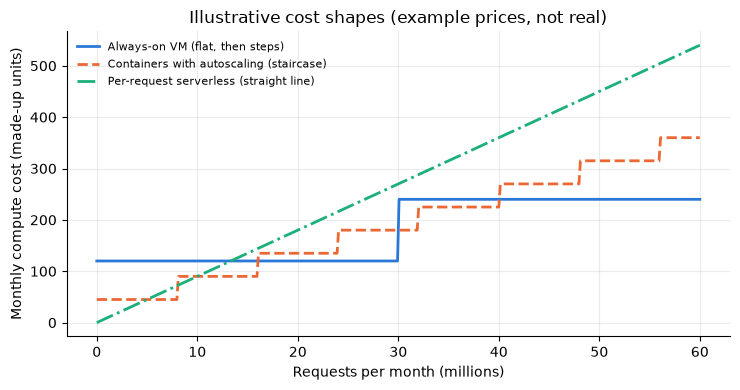

In [7]:
# Made-up example prices (NOT real prices), chosen only to show the shape of each curve.
VM_MONTHLY        = 120.0     # one always-on VM that can serve up to VM_CAPACITY requests/month
VM_CAPACITY       = 30e6
TASK_MONTHLY      = 45.0      # one container task running all month
TASK_CAPACITY     = 8e6       # requests one task can serve per month
MIN_TASKS         = 1
SERVERLESS_PER_M  = 9.0       # per 1 million requests (request fee + compute time, rolled together)

reqs = np.linspace(0, 60e6, 400)                       # requests per month
vm_cost = VM_MONTHLY * np.ceil(np.maximum(reqs, 1) / VM_CAPACITY)
tasks = np.maximum(MIN_TASKS, np.ceil(reqs / TASK_CAPACITY))
container_cost = TASK_MONTHLY * tasks
serverless_cost = SERVERLESS_PER_M * reqs / 1e6

def first_cross(a, b):
    """First request volume where curve a becomes more expensive than curve b."""
    idx = np.where(a > b)[0]
    return reqs[idx[0]] if len(idx) else None

print(f"Serverless becomes dearer than containers at about {first_cross(serverless_cost, container_cost)/1e6:.1f} M requests/month")
print(f"Serverless becomes dearer than one VM at about   {first_cross(serverless_cost, vm_cost)/1e6:.1f} M requests/month")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(reqs / 1e6, vm_cost, color="#2a78d6", lw=2, label="Always-on VM (flat, then steps)")
ax.plot(reqs / 1e6, container_cost, color="#eb6834", lw=2, ls="--", label="Containers with autoscaling (staircase)")
ax.plot(reqs / 1e6, serverless_cost, color="#1baf7a", lw=2, ls="-.", label="Per-request serverless (straight line)")
ax.set_xlabel("Requests per month (millions)")
ax.set_ylabel("Monthly compute cost (made-up units)")
ax.set_title("Illustrative cost shapes (example prices, not real)")
ax.grid(alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**How to read the plot.** At low traffic, serverless (green) is close to free while the VM (blue) and the minimum container task (orange) cost a fixed amount even when nobody calls. As traffic grows, the green line climbs steadily and crosses the others. The VM looks cheapest at high steady load, but remember what the flat line does not show: your time patching it, and the risk of one machine failing.

**When to use which (rule of thumb):**

| Traffic pattern | Usually cheapest and simplest |
|---|---|
| Rare or very spiky, short requests | Functions or scale-to-zero containers |
| Business-hours traffic, moderate | Serverless containers with a small minimum |
| High and steady, 24/7 | Containers on reserved/committed VMs, or Kubernetes with committed nodes |
| GPU serving with real traffic | Dedicated GPU capacity (endpoint, Kubernetes node pool, or GPU VMs) with autoscaling; scale-to-zero GPU only if you can accept long cold starts |

More on discounts (Savings Plans, committed use discounts, reservations, Spot) in [04 cloud cost optimization](./04_cloud_cost_optimization.ipynb).

## 3. Databases and storage: where your data lives

An AI application usually needs **several** stores, not one. A typical RAG chat app keeps users and billing in a relational database, chat history in a document or key-value store, embeddings in a vector index, hot answers in a cache, logs in a warehouse and uploaded PDFs in object storage. This section helps you pick each one.

Deep dives in the repo: [13_Databases](../13_Databases/) (SQL, NoSQL, vector, graph, time-series), [vector databases](../13_Databases/03_vector_db/01_vector_databases.ipynb), AWS data services in [06, section 6](./06_aws_core_services_for_ai_engineers.ipynb), Google Cloud in [10, section 6](./10_gcp_core_services_for_ai_engineers.ipynb), Azure in [08, section 10](./08_azure_core_services_for_ai_engineers.ipynb).

### 3.1 Words you need first

**Data models** (the "shape" of the data):

| Model | What it is (one line) | Analogy | Example need in an AI app |
|---|---|---|---|
| Relational (SQL) | Tables with rows, columns, joins and transactions | A spreadsheet with strict rules that links sheets together | Users, plans, invoices, API keys |
| Key-value | Look up a value by its key, very fast | A coat check: ticket number -> coat | Session state, rate-limit counters |
| Document | Store flexible JSON documents | A folder of forms that can have different fields | Chat history, agent memory, user settings |
| Wide-column | Huge sparse tables keyed by row and column family | A giant ledger sorted by key | Feature store, time-ordered events at massive scale |
| Graph | Nodes and edges, query by relationships | A map of who knows whom | Knowledge graphs, GraphRAG, fraud rings |
| Time-series | Values indexed by time, with roll-ups | A heart-rate monitor | Metrics, sensor data, token usage over time |
| Search / vector | Full-text and similarity search over an index | A library catalogue that also finds "books like this one" | Retrieval for RAG (keyword + vector, hybrid) |
| Cache (in-memory) | Data kept in RAM for sub-millisecond reads | A sticky note on your monitor | Cached LLM answers, rate limits, hot lookups |
| Warehouse (analytics) | Column-based store for big scans and aggregates | A statistics office | Usage dashboards, cost reports, evaluation analysis |
| Object storage | Files ("objects") in buckets, by key, via HTTP | A huge self-storage building | PDFs, images, model weights, datasets |
| Block storage | A virtual disk attached to one VM | A USB hard drive | A VM's root disk, a database's data volume |
| File storage | A shared network file system (NFS/SMB) | A shared drive in an office | Shared model cache for many workers, training data |

**Consistency** (what you see right after a write):
- **Strong consistency:** every read sees the latest write. Simple to reason about; can cost latency, especially across regions.
- **Eventual consistency:** reads may be slightly stale for a short time, then catch up. Faster and more available; your code must tolerate stale reads.
- Many services let you choose per request (DynamoDB "strongly consistent read") or per account (Cosmos DB has five levels: strong, bounded staleness, session, consistent prefix, eventual).

**Scaling styles:**
- **Vertical:** a bigger machine. Simple, has a ceiling.
- **Read replicas:** copies that serve reads; writes still go to one primary.
- **Sharding / partitioning:** split data by a key across many machines. Scales very far, but you must pick a good partition key.
- **Serverless capacity:** the service adds capacity automatically and bills per use (Aurora Serverless v2, DynamoDB on-demand, Firestore, Cosmos DB serverless).

### 3.2 AWS databases and storage

Short notes, then one table.
- **Amazon RDS:** managed relational databases (PostgreSQL, MySQL, MariaDB, SQL Server, Oracle, Db2). AWS handles backups, patching, Multi-AZ failover and read replicas. **pgvector** works on RDS for PostgreSQL.
- **Amazon Aurora:** AWS's cloud-built MySQL- and PostgreSQL-compatible engine with storage replicated across three AZs, fast replicas and **Aurora Serverless v2** (capacity scales in small steps, and can scale down to zero when idle in supported versions). Aurora PostgreSQL with pgvector is a common RAG store and a supported Bedrock Knowledge Bases vector store.
- **Amazon Aurora DSQL:** a serverless, distributed, PostgreSQL-compatible SQL database. Active-active across AZs or across Regions (within one "Region set", such as North America), with strong consistency. Good for global apps that must keep writing during a Region problem; not every PostgreSQL feature is supported, so check compatibility.
- **Amazon DynamoDB:** serverless key-value and document database. Single-digit-millisecond reads at any scale, on-demand or provisioned capacity, global tables, streams, TTL. You must design around access patterns (partition key, sort key).
- **Amazon DocumentDB (with MongoDB compatibility):** managed document database that speaks the MongoDB API.
- **Amazon Neptune:** managed graph database (property graph with Gremlin/openCypher, and RDF/SPARQL). **Neptune Analytics** is the in-memory analytics and vector option used for GraphRAG.
- **Amazon Keyspaces (for Apache Cassandra):** serverless wide-column, Cassandra-compatible.
- **Amazon Timestream:** time-series. **Timestream for LiveAnalytics stopped accepting new customers on 20 June 2025**; AWS recommends **Timestream for InfluxDB** for new time-series work.
- **Amazon ElastiCache:** managed in-memory cache with **Valkey** (the open-source Redis fork AWS now leads with), Redis OSS or Memcached; has a serverless option. **Amazon MemoryDB** is a durable, Redis/Valkey-compatible in-memory *database* (data survives restarts) with vector search.
- **Amazon OpenSearch Service:** managed OpenSearch for full-text, log analytics and vector search (k-NN), with an **OpenSearch Serverless** option. The default store for hybrid (keyword + vector) search in Bedrock Knowledge Bases.
- **Amazon Redshift:** the data warehouse (provisioned or Serverless).
- **Amazon S3:** object storage, with storage classes from Standard to Intelligent-Tiering, Infrequent Access and the **S3 Glacier** archive classes (Instant Retrieval, Flexible Retrieval, Deep Archive). **Amazon S3 Vectors** (GA Dec 2025) stores and queries vector embeddings directly in special "vector buckets" at low cost, for large but not ultra-low-latency vector search.
- **Amazon EBS** (block disks for EC2), **Amazon EFS** (shared NFS file system, elastic), **Amazon FSx** (managed file systems: FSx for Lustre for fast training data, plus NetApp ONTAP, OpenZFS and Windows File Server).

In [8]:
aws_data = pd.DataFrame([
    ["RDS (Postgres/MySQL)", "Relational",              "Strong on primary; replicas lag", "Vertical + read replicas",          "Users, billing, app data; pgvector for small/medium RAG"],
    ["Aurora (+ Serverless v2)", "Relational",          "Strong on writer; fast replicas", "Replicas; serverless capacity",     "Same as RDS at higher scale; pgvector RAG store"],
    ["Aurora DSQL",          "Distributed relational",  "Strong, multi-Region active-active", "Automatic, serverless",          "Global apps that must keep writing in two Regions"],
    ["DynamoDB",             "Key-value / document",    "Eventual by default; strong option", "Partitioning, on-demand",       "Chat history, sessions, agent state, idempotency keys"],
    ["DocumentDB",           "Document (MongoDB API)",  "Strong on primary",               "Replicas; elastic clusters",        "Teams moving MongoDB apps to AWS"],
    ["Neptune / Neptune Analytics", "Graph",            "Strong on primary",               "Replicas; in-memory analytics",     "Knowledge graphs, GraphRAG"],
    ["Keyspaces",            "Wide-column (Cassandra)", "Tunable (LOCAL_QUORUM etc.)",     "Serverless",                        "Cassandra workloads"],
    ["Timestream for InfluxDB", "Time-series",          "Strong (single instance/cluster)","Instance size",                     "Metrics, sensor data (LiveAnalytics closed to new customers)"],
    ["ElastiCache (Valkey/Redis OSS/Memcached)", "In-memory cache", "Async replicas",     "Shards + replicas; serverless",     "Response cache, rate limits, semantic cache"],
    ["MemoryDB",             "Durable in-memory DB",    "Strong on primary (durable log)", "Shards + replicas",                 "Fast durable state; in-memory vector search"],
    ["OpenSearch Service / Serverless", "Search + vector", "Near real-time (refresh)",    "Shards; serverless collections",    "Hybrid keyword + vector retrieval, log search"],
    ["Redshift (Serverless)", "Warehouse",              "Strong",                          "Compute scales separately",        "Usage analytics, cost and eval dashboards"],
    ["S3",                   "Object",                  "Strong read-after-write",         "Practically unlimited",            "Documents, images, model weights, data lake"],
    ["S3 Vectors",           "Vector index in object storage", "(check docs)",             "Up to billions of vectors per index", "Large, cost-sensitive vector search"],
    ["S3 Glacier classes",   "Archive object",          "Strong",                          "Unlimited",                        "Old logs, raw data you must keep for years"],
    ["EBS",                  "Block (one VM)",          "Strong",                          "Per-volume size / IOPS",           "VM disks, self-managed DBs"],
    ["EFS",                  "File (NFS, shared)",      "Strong (close-to-open)",          "Elastic",                          "Shared model cache across containers"],
    ["FSx for Lustre",       "File (HPC)",              "Strong",                          "Throughput tiers",                 "Feeding GPUs fast during training"],
], columns=["Service", "Data model", "Consistency", "Scaling", "Typical AI-app use"])
show(aws_data)

                                 Service                     Data model                        Consistency                             Scaling                                           Typical AI-app use
                    RDS (Postgres/MySQL)                     Relational    Strong on primary; replicas lag            Vertical + read replicas      Users, billing, app data; pgvector for small/medium RAG
                Aurora (+ Serverless v2)                     Relational    Strong on writer; fast replicas       Replicas; serverless capacity              Same as RDS at higher scale; pgvector RAG store
                             Aurora DSQL         Distributed relational Strong, multi-Region active-active               Automatic, serverless            Global apps that must keep writing in two Regions
                                DynamoDB           Key-value / document Eventual by default; strong option             Partitioning, on-demand        Chat history, sessions, agent stat

### 3.3 Google Cloud and Azure equivalents

**Google Cloud**
- **Cloud SQL:** managed PostgreSQL, MySQL, SQL Server (pgvector supported).
- **AlloyDB for PostgreSQL:** Google's high-performance PostgreSQL-compatible engine, with AlloyDB AI (vector search with ScaNN-based indexes, in-database model calls). Match for Aurora.
- **Spanner:** globally distributed relational database with strong consistency (external consistency) and very high availability. The match for Aurora DSQL (and for DynamoDB global tables when you need SQL).
- **Firestore:** serverless document database (Native mode, and a MongoDB-compatible mode). Match for DynamoDB/DocumentDB for app data and chat history.
- **Bigtable:** wide-column at huge scale, low latency (HBase API). Match for Keyspaces/DynamoDB at massive scale.
- **Memorystore:** managed Valkey, Redis and Memcached. Match for ElastiCache.
- **BigQuery:** serverless warehouse, with BigQuery ML and **vector search** in SQL. Match for Redshift.
- **Vector Search** on Agent Platform (formerly Vertex AI Vector Search) for large low-latency vector retrieval.
- **Cloud Storage:** object storage (Standard, Nearline, Coldline, Archive classes, plus Autoclass). **Persistent Disk / Hyperdisk** for block, **Filestore** for NFS, **Managed Lustre** for HPC.

**Azure**
- **Azure SQL Database / SQL Managed Instance:** managed SQL Server engine (serverless tier available).
- **Azure Database for PostgreSQL Flexible Server** and **for MySQL Flexible Server:** managed open-source engines (pgvector and DiskANN-based indexes on PostgreSQL).
- **Azure Cosmos DB:** globally distributed multi-model database with several APIs: **NoSQL** (recommended for new apps; has vector and hybrid search), **MongoDB (RU)**, **Cassandra**, **Gremlin** (graph) and **Table**. The vCore-based MongoDB offering is now called **Azure DocumentDB**. Five consistency levels.
- **Azure Managed Redis:** the managed Redis service going forward (the older Azure Cache for Redis tiers are retiring between 2027 and 2028).
- **Azure AI Search** (also branded **Foundry IQ** as of late 2025): full-text, vector and hybrid search with semantic ranking. Match for OpenSearch.
- **Microsoft Fabric** and **Azure Synapse Analytics:** analytics and warehousing. Microsoft positions Fabric as the direction for new analytics work; Synapse still runs. **Azure Data Explorer** for log and time-series analytics.
- **Azure Blob Storage** (hot, cool, cold, archive tiers; Data Lake Storage Gen2), **Azure Files** (SMB/NFS shares), **Managed Disks** (block), **Azure NetApp Files** and **Azure Managed Lustre** (HPC file).

In [9]:
data_map = pd.DataFrame([
    ["Managed PostgreSQL/MySQL",      "RDS",                               "Cloud SQL",                          "Database for PostgreSQL/MySQL Flexible Server"],
    ["Cloud-tuned PostgreSQL",        "Aurora PostgreSQL (Serverless v2)", "AlloyDB for PostgreSQL",             "Azure Database for PostgreSQL (Flexible)"],
    ["Managed SQL Server",            "RDS for SQL Server",                "Cloud SQL for SQL Server",           "Azure SQL Database / Managed Instance"],
    ["Globally distributed SQL",      "Aurora DSQL",                       "Spanner",                            "Cosmos DB (NoSQL) / Azure SQL Hyperscale (not identical)"],
    ["Serverless key-value/document", "DynamoDB",                          "Firestore",                          "Cosmos DB for NoSQL"],
    ["MongoDB-compatible",            "DocumentDB",                        "Firestore with MongoDB compatibility","Azure DocumentDB / Cosmos DB for MongoDB (RU)"],
    ["Wide-column",                   "Keyspaces",                         "Bigtable",                           "Cosmos DB for Apache Cassandra / Managed Instance for Cassandra"],
    ["Graph",                         "Neptune",                           "Spanner Graph",                      "Cosmos DB for Apache Gremlin"],
    ["Time-series",                   "Timestream for InfluxDB",           "Bigtable / BigQuery",                "Azure Data Explorer"],
    ["In-memory cache",               "ElastiCache (Valkey/Redis OSS)",    "Memorystore (Valkey/Redis)",         "Azure Managed Redis"],
    ["Search + vector index",         "OpenSearch Service",                "Agent Platform Vector Search / Agent Search", "Azure AI Search (Foundry IQ)"],
    ["Vector inside Postgres",        "pgvector on RDS/Aurora",            "pgvector / AlloyDB AI",              "pgvector / DiskANN on PostgreSQL Flexible"],
    ["Vectors in object storage",     "S3 Vectors",                        "(no direct match)",                  "(no direct match)"],
    ["Data warehouse",                "Redshift",                          "BigQuery",                           "Microsoft Fabric / Synapse"],
    ["Object storage",                "S3",                                "Cloud Storage",                      "Blob Storage"],
    ["Archive storage",               "S3 Glacier classes",                "Cloud Storage Archive class",        "Blob archive tier"],
    ["Block disks",                   "EBS",                               "Persistent Disk / Hyperdisk",        "Managed Disks"],
    ["Shared file (NFS/SMB)",         "EFS / FSx",                         "Filestore",                          "Azure Files / Azure NetApp Files"],
    ["HPC file system",               "FSx for Lustre",                    "Managed Lustre",                     "Azure Managed Lustre"],
], columns=["Need", "AWS", "Google Cloud", "Azure"])
show(data_map)

                         Need                               AWS                                Google Cloud                                                           Azure
     Managed PostgreSQL/MySQL                               RDS                                   Cloud SQL                   Database for PostgreSQL/MySQL Flexible Server
       Cloud-tuned PostgreSQL Aurora PostgreSQL (Serverless v2)                      AlloyDB for PostgreSQL                        Azure Database for PostgreSQL (Flexible)
           Managed SQL Server                RDS for SQL Server                    Cloud SQL for SQL Server                           Azure SQL Database / Managed Instance
     Globally distributed SQL                       Aurora DSQL                                     Spanner        Cosmos DB (NoSQL) / Azure SQL Hyperscale (not identical)
Serverless key-value/document                          DynamoDB                                   Firestore                                 

### 3.4 Which store for which AI-app job?

| AI-app job | What matters | Good default | Also fine | Avoid |
|---|---|---|---|---|
| Users, billing, API keys, tenants | Transactions, joins, constraints | Managed PostgreSQL (RDS/Aurora, Cloud SQL/AlloyDB, PostgreSQL Flexible) | MySQL, Azure SQL | Putting money in an eventually consistent store |
| Chat history, agent memory | Fast append and read by user/session, flexible JSON | DynamoDB / Firestore / Cosmos DB for NoSQL | A `messages` table in Postgres (fine for small apps) | Storing whole conversations in one giant row |
| Embeddings / vector search | Similarity search, filters, hybrid search, scale | pgvector in your Postgres (small/medium) | OpenSearch / Azure AI Search / Agent Platform Vector Search (hybrid, large); S3 Vectors (huge, cheap, slower) | A separate vector DB on day one when 100k vectors fit in Postgres |
| Caching answers, rate limits | Sub-millisecond reads, TTL | ElastiCache (Valkey) / Memorystore / Azure Managed Redis | DynamoDB with TTL | Caching personal data without a TTL |
| Logs, usage and cost analytics | Big scans, aggregates, cheap storage | Redshift / BigQuery / Fabric, fed from object storage | OpenSearch for log search; CloudWatch Logs / Cloud Logging / Log Analytics | Running heavy analytics on the production OLTP database |
| Uploaded files, model weights, datasets | Cheap, durable, HTTP access | S3 / Cloud Storage / Blob Storage | Shared file system (EFS, Filestore, Azure Files) when tools need a POSIX path | Storing files as BLOBs inside the relational DB |
| Knowledge graph / GraphRAG | Relationship queries | Neptune / Spanner Graph / Cosmos DB Gremlin | A graph library over Postgres for small graphs | A graph DB when you only have tables |

### 3.5 Runnable: what "eventual consistency" feels like

**What it is:** a primary database and one read replica. Writes go to the primary; the replica copies them after a delay ("replication lag"). If you read from the replica straight after writing, you may see old data.

**Why it matters for AI apps:** a user sends a message, the app writes it, then immediately reloads the chat from a replica, and the message is missing. Fixes: read your own writes from the primary, use a strongly consistent read option, or use "session" consistency (Cosmos DB) so a user always sees their own writes.

In [10]:
class Primary:
    def __init__(self):
        self.data = {}
        self.log = []              # (time_written, key, value)
    def write(self, t, key, value):
        self.data[key] = value
        self.log.append((t, key, value))

class Replica:
    def __init__(self, primary, lag_s):
        self.p, self.lag, self.data = primary, lag_s, {}
    def read(self, t, key):
        # apply every change that is at least `lag` seconds old
        for (tw, k, v) in self.p.log:
            if tw + self.lag <= t:
                self.data[k] = v
        return self.data.get(key)

p = Primary()
r = Replica(p, lag_s=0.3)
p.write(0.00, "chat:42:last_msg", "hello")
p.write(1.00, "chat:42:last_msg", "what is RAG?")
for t in [1.05, 1.20, 1.35, 2.00]:
    print(f"t={t:.2f}s  primary={p.data['chat:42:last_msg']!r:16}  replica={r.read(t, 'chat:42:last_msg')!r}")
print("\nThe replica shows the old message until the lag (0.3 s) has passed.")

t=1.05s  primary='what is RAG?'    replica='hello'
t=1.20s  primary='what is RAG?'    replica='hello'
t=1.35s  primary='what is RAG?'    replica='what is RAG?'
t=2.00s  primary='what is RAG?'    replica='what is RAG?'

The replica shows the old message until the lag (0.3 s) has passed.


### 3.6 Runnable: a "pick a database" chooser

**What it is:** a scoring function. You describe a workload with a few traits; each candidate store gets points for traits it is good at and loses points for traits it is bad at. The best score wins, and the function prints the names on each cloud.

It is deliberately simple and opinionated. The aim is to make the trade-offs visible, not to replace a design review.

In [11]:
STORES = {
    # name: (AWS, Google Cloud, Azure, strengths, weaknesses)
    "relational":  ("RDS / Aurora PostgreSQL", "Cloud SQL / AlloyDB", "PostgreSQL Flexible / Azure SQL",
                    {"transactions", "joins", "small_vectors", "reporting_light"}, {"massive_scale_kv", "huge_vectors"}),
    "global_sql":  ("Aurora DSQL", "Spanner", "Cosmos DB / SQL Hyperscale",
                    {"transactions", "multi_region_writes", "joins"}, {"low_budget"}),
    "key_value":   ("DynamoDB", "Firestore", "Cosmos DB for NoSQL",
                    {"massive_scale_kv", "flexible_json", "serverless", "multi_region_writes"}, {"joins", "ad_hoc_queries"}),
    "cache":       ("ElastiCache (Valkey)", "Memorystore", "Azure Managed Redis",
                    {"sub_ms_reads", "ttl"}, {"durability_required", "ad_hoc_queries"}),
    "search_vec":  ("OpenSearch Service", "Agent Platform Vector Search", "Azure AI Search",
                    {"huge_vectors", "hybrid_search", "full_text"}, {"transactions"}),
    "object_vec":  ("S3 Vectors", "(Cloud Storage + Vector Search)", "(Blob + AI Search)",
                    {"huge_vectors", "low_budget"}, {"sub_ms_reads", "hybrid_search"}),
    "warehouse":   ("Redshift", "BigQuery", "Microsoft Fabric",
                    {"ad_hoc_queries", "big_scans", "reporting_light"}, {"sub_ms_reads", "transactions"}),
    "graph":       ("Neptune", "Spanner Graph", "Cosmos DB for Gremlin",
                    {"relationships"}, {"big_scans"}),
    "object":      ("S3", "Cloud Storage", "Blob Storage",
                    {"files", "low_budget", "durability_required"}, {"sub_ms_reads", "transactions"}),
}

def pick_database(traits):
    traits = set(traits)
    scores = []
    for name, (aws, gcp, az, good, bad) in STORES.items():
        s = 2 * len(traits & good) - 3 * len(traits & bad)
        scores.append((s, name, aws, gcp, az, sorted(traits & good), sorted(traits & bad)))
    scores.sort(key=lambda x: -x[0])
    return scores[0]

cases = {
    "Users + billing":                  {"transactions", "joins"},
    "Chat history for 10M users":       {"massive_scale_kv", "flexible_json", "serverless"},
    "Semantic cache of LLM answers":    {"sub_ms_reads", "ttl"},
    "RAG over 50k docs":                {"small_vectors", "transactions"},
    "RAG over 500M chunks, hybrid":     {"huge_vectors", "hybrid_search", "full_text"},
    "Archive-scale vectors, cheap":     {"huge_vectors", "low_budget"},
    "Token usage dashboards":           {"ad_hoc_queries", "big_scans"},
    "Uploaded PDFs":                    {"files", "durability_required"},
    "Global app, writes in 2 regions":  {"transactions", "multi_region_writes"},
    "Knowledge graph for GraphRAG":     {"relationships"},
}
rows = []
for case, tr in cases.items():
    s, name, aws, gcp, az, good, bad = pick_database(tr)
    rows.append([case, name, aws, gcp, az, ", ".join(good)])
show(pd.DataFrame(rows, columns=["Workload", "Store type", "AWS", "Google Cloud", "Azure", "Matched strengths"]))

                       Workload Store type                     AWS                    Google Cloud                           Azure                           Matched strengths
                Users + billing relational RDS / Aurora PostgreSQL             Cloud SQL / AlloyDB PostgreSQL Flexible / Azure SQL                         joins, transactions
     Chat history for 10M users  key_value                DynamoDB                       Firestore             Cosmos DB for NoSQL flexible_json, massive_scale_kv, serverless
  Semantic cache of LLM answers      cache    ElastiCache (Valkey)                     Memorystore             Azure Managed Redis                           sub_ms_reads, ttl
              RAG over 50k docs relational RDS / Aurora PostgreSQL             Cloud SQL / AlloyDB PostgreSQL Flexible / Azure SQL                 small_vectors, transactions
   RAG over 500M chunks, hybrid search_vec      OpenSearch Service    Agent Platform Vector Search                 Azure AI S

## 4. Messaging and events: how parts talk to each other

AI work is often slow (a model call can take seconds, a document ingest can take minutes). Messaging services let one part of your system hand work to another **without waiting**, absorb bursts, and retry failures. There are four basic delivery models. Once you know them, every cloud product is just one of these four with extra features.

Deep dives: [message queues](../16_Deployment/message_queues/01_message_queues.ipynb); AWS integration in [06, section 7](./06_aws_core_services_for_ai_engineers.ipynb) (SQS visibility timeout, EventBridge rules, Step Functions); Azure Service Bus in [08, section 11](./08_azure_core_services_for_ai_engineers.ipynb); Google Cloud in [10, section 7](./10_gcp_core_services_for_ai_engineers.ipynb).

### 4.1 Queue vs topic vs stream vs workflow

| Model | What it is | Analogy | Who gets each message | Can you replay old messages? | AI example |
|---|---|---|---|---|---|
| **Queue** | A to-do list; each item is handled by **one** worker, then deleted | Tickets at a deli counter: one server takes each ticket | One consumer (competing consumers share the load) | No (once deleted, gone) | "Embed this uploaded document" jobs |
| **Topic (pub/sub)** | A broadcast; each message is **copied** to every subscriber | A newsletter: everyone subscribed gets a copy | Every subscription gets its own copy | Usually no (some keep a short retention) | "New document uploaded" -> indexer, virus scanner, audit log |
| **Stream** | An append-only log kept for a time; readers track their own position (offset) | A ship's logbook: anyone can read from any page, and pages stay | Every consumer group reads everything at its own pace | Yes, within the retention period | Clickstream / token-usage events for analytics and features |
| **Workflow** | A defined list of steps with state, retries, branches and waits | A recipe card with a timer, followed by a careful cook | Steps call services in order | The run history is kept | "Parse PDF -> chunk -> embed -> index -> notify" with retries |

```mermaid
flowchart LR
    subgraph Queue
      P1[Producer] --> Q[(Queue)] --> W1[Worker A]
      Q --> W2[Worker B]
    end
    subgraph Topic
      P2[Publisher] --> T((Topic)) --> S1[Sub: indexer]
      T --> S2[Sub: audit]
      T --> S3[Sub: email]
    end
    subgraph Stream
      P3[Producers] --> L[[Log: partition 0..n]] --> G1[Group: analytics @offset 120]
      L --> G2[Group: features @offset 87]
    end
```

**Key queue words:**
- **Visibility timeout / lock:** when a worker takes a message, it is hidden from others for a while. If the worker finishes, it deletes the message. If it crashes, the message reappears and another worker tries.
- **At-least-once delivery:** a message may arrive twice, so handlers must be **idempotent** (safe to run twice, for example by checking a "done" key first).
- **Dead-letter queue (DLQ):** after N failed attempts, the message is moved aside for a human to inspect instead of blocking the queue forever.
- **FIFO / ordering:** strict order (often per group key) and de-duplication, usually at lower throughput than standard queues.

### 4.2 The services on each cloud

**AWS**
- **Amazon SQS:** the queue. **Standard** queues: nearly unlimited throughput, at-least-once, best-effort order. **FIFO** queues: strict order per message group and de-duplication. Visibility timeout, long polling, delay queues, **DLQ** with a redrive policy. Message size is limited, so large payloads go to S3 and the message carries a pointer.
- **Amazon SNS:** the topic. Fan-out to SQS, Lambda, HTTP endpoints, email and SMS; **subscription filter policies** send each subscriber only what it wants. FIFO topics exist for ordered fan-out into FIFO queues. (For sending email to *customers*, use SES, not SNS; see section 5.)
- **Amazon EventBridge:** an **event bus** with **rules** that match on event content (event patterns) and route to targets; receives events from AWS services and SaaS partners; archive and replay; schema registry. **EventBridge Scheduler** runs one-off or cron schedules at scale. **EventBridge Pipes** connect a source (such as a queue or stream) to a target with filtering and enrichment.
- **Amazon Kinesis Data Streams:** the stream. Shards (or on-demand capacity), ordering per partition key, replay within the retention period. **Amazon Data Firehose** (formerly Kinesis Data Firehose) loads streaming data into S3, Redshift, OpenSearch and others with no code.
- **Amazon MSK (Managed Streaming for Apache Kafka):** managed Kafka, including MSK Serverless. Pick it when you already use Kafka tools.
- **Amazon MQ:** managed ActiveMQ and RabbitMQ, mostly for moving existing apps that speak AMQP/MQTT/STOMP/JMS.
- **AWS Step Functions:** the workflow engine. **Standard** workflows (long-running, up to a year, exactly-once step execution, full history) and **Express** workflows (high-volume, short, at-least-once). Direct integrations with many AWS services, including Bedrock.

**Google Cloud**
- **Pub/Sub:** one service that covers topics *and* queues: each **subscription** behaves like a queue (pull or push), and many subscriptions on one topic give fan-out. Ordering keys, dead-letter topics, exactly-once delivery (pull), message retention and seek (replay), and export subscriptions straight to BigQuery or Cloud Storage. (Pub/Sub Lite is deprecated; use Pub/Sub or Managed Service for Apache Kafka.)
- **Cloud Tasks:** a queue where *you* say exactly which HTTP endpoint gets each task, with rate limits, retries and scheduled delivery. Good for "call my worker at most 5 times per second".
- **Eventarc:** event routing from Google services, Pub/Sub and partners to Cloud Run, Workflows and others (Eventarc Standard, and Eventarc Advanced as a central bus with policies).
- **Workflows:** serverless step orchestration in YAML/JSON. **Cloud Scheduler** for cron. **Managed Service for Apache Kafka** for Kafka.

**Azure**
- **Azure Service Bus:** enterprise messaging with **queues** and **topics/subscriptions**, peek-lock, sessions (ordered groups), duplicate detection, scheduled messages and a built-in **dead-letter queue**.
- **Azure Storage Queues:** a very simple, cheap queue inside a storage account. Fine for basic background work; fewer features than Service Bus.
- **Azure Event Grid:** push-style event routing (resource events such as "blob created", custom topics), with filters and retries; **namespaces** add pull delivery and MQTT.
- **Azure Event Hubs:** the stream (partitions, consumer groups, retention, capture to storage) with a **Kafka-compatible endpoint**.
- **Azure Logic Apps:** low-code workflows with hundreds of connectors. **Durable Functions:** code-first stateful workflows inside Azure Functions.

In [12]:
msg_map = pd.DataFrame([
    ["Work queue",                      "SQS (Standard)",            "Pub/Sub subscription / Cloud Tasks", "Service Bus queue / Storage Queues", "One worker per message; retries; DLQ"],
    ["Ordered, de-duplicated queue",    "SQS FIFO",                  "Pub/Sub ordering keys",              "Service Bus sessions + duplicate detection", "Order per key; lower throughput"],
    ["Rate-limited HTTP dispatch",      "SQS + Lambda concurrency limit", "Cloud Tasks",                   "Service Bus + Functions concurrency", "Protects a slow model API"],
    ["Fan-out topic",                   "SNS",                       "Pub/Sub topic (many subscriptions)", "Service Bus topic / Event Grid topic", "Every subscriber gets a copy"],
    ["Event bus with content rules",    "EventBridge",               "Eventarc",                           "Event Grid",                          "Route by event fields; SaaS + cloud events"],
    ["Scheduler / cron",                "EventBridge Scheduler",     "Cloud Scheduler",                    "Logic Apps recurrence / Functions timer", "Nightly re-index, reports"],
    ["Stream (replayable log)",         "Kinesis Data Streams",      "Pub/Sub (retention + seek) / Managed Kafka", "Event Hubs",                "Analytics, features, audit"],
    ["Managed Kafka",                   "Amazon MSK",                "Managed Service for Apache Kafka",   "Event Hubs (Kafka endpoint) / Confluent on Azure", "Existing Kafka tooling"],
    ["Stream -> storage, no code",      "Amazon Data Firehose",      "Pub/Sub BigQuery / Cloud Storage subscriptions", "Event Hubs Capture",       "Land events in a lake/warehouse"],
    ["Classic broker (AMQP, JMS)",      "Amazon MQ",                 "(Marketplace / self-managed)",       "Service Bus (AMQP 1.0)",              "Lift-and-shift of older apps"],
    ["Workflow orchestration",          "Step Functions",            "Workflows",                          "Logic Apps / Durable Functions",      "Multi-step pipelines with retries"],
], columns=["Need", "AWS", "Google Cloud", "Azure", "Notes"])
show(msg_map)

                        Need                            AWS                                   Google Cloud                                            Azure                                      Notes
                  Work queue                 SQS (Standard)             Pub/Sub subscription / Cloud Tasks               Service Bus queue / Storage Queues       One worker per message; retries; DLQ
Ordered, de-duplicated queue                       SQS FIFO                          Pub/Sub ordering keys       Service Bus sessions + duplicate detection            Order per key; lower throughput
  Rate-limited HTTP dispatch SQS + Lambda concurrency limit                                    Cloud Tasks              Service Bus + Functions concurrency                  Protects a slow model API
               Fan-out topic                            SNS             Pub/Sub topic (many subscriptions)             Service Bus topic / Event Grid topic               Every subscriber gets a copy
Event

### 4.3 Runnable: a mini simulation of each delivery model

Four tiny in-memory classes. They are not production code; they show the *behaviour* that makes each model different. Time is simulated with a counter, so the output is the same every run.

**(a) Queue** with competing consumers, a visibility timeout, retries and a dead-letter queue.

In [13]:
class ToyQueue:
    def __init__(self, visibility_timeout=3, max_receives=3):
        self.msgs = {}                 # id -> dict(body, visible_at, receives)
        self.dlq = []
        self.vt, self.max_receives = visibility_timeout, max_receives
        self._next = 0
    def send(self, body):
        self.msgs[self._next] = dict(body=body, visible_at=0, receives=0); self._next += 1
    def receive(self, now):
        for mid, m in sorted(self.msgs.items()):
            if m["visible_at"] <= now:
                m["receives"] += 1
                if m["receives"] > self.max_receives:      # too many tries -> dead-letter queue
                    self.dlq.append(m["body"]); del self.msgs[mid]; continue
                m["visible_at"] = now + self.vt            # hide it from other workers
                return mid, m["body"], m["receives"]
        return None
    def delete(self, mid):
        self.msgs.pop(mid, None)

q = ToyQueue()
for doc in ["doc-1", "doc-2", "doc-3 (corrupt)", "doc-4"]:
    q.send(doc)

done = set()                    # idempotency: remember finished work
for now in range(0, 16):
    for worker in ["A", "B"]:
        got = q.receive(now)
        if not got:
            continue
        mid, body, n = got
        if "corrupt" in body:
            print(f"t={now:2d} worker {worker} FAILED {body} (attempt {n}); message will reappear after timeout")
            continue                                   # no delete -> it becomes visible again
        if body in done:
            print(f"t={now:2d} worker {worker} skipped duplicate {body}")
        else:
            done.add(body); print(f"t={now:2d} worker {worker} embedded {body}")
        q.delete(mid)
print("\nDead-letter queue:", q.dlq, "| still in queue:", len(q.msgs))

t= 0 worker A embedded doc-1
t= 0 worker B embedded doc-2
t= 1 worker A FAILED doc-3 (corrupt) (attempt 1); message will reappear after timeout
t= 1 worker B embedded doc-4
t= 4 worker A FAILED doc-3 (corrupt) (attempt 2); message will reappear after timeout
t= 7 worker A FAILED doc-3 (corrupt) (attempt 3); message will reappear after timeout

Dead-letter queue: ['doc-3 (corrupt)'] | still in queue: 0


**(b) Topic** with fan-out and a subscription filter (like an SNS filter policy or an Event Grid / Pub/Sub filter).

In [14]:
class ToyTopic:
    def __init__(self):
        self.subs = {}                          # name -> (filter function, inbox list)
    def subscribe(self, name, filt=lambda m: True):
        self.subs[name] = (filt, [])
    def publish(self, msg):
        for name, (filt, inbox) in self.subs.items():
            if filt(msg):
                inbox.append(msg)               # each subscriber gets its OWN copy

t = ToyTopic()
t.subscribe("indexer")                                            # wants everything
t.subscribe("virus-scan", lambda m: m["type"] in {"pdf", "docx"})  # only documents
t.subscribe("audit-log")
t.subscribe("big-file-alert", lambda m: m["size_mb"] > 50)

for m in [dict(type="pdf", name="policy.pdf", size_mb=3),
          dict(type="png", name="logo.png", size_mb=0.2),
          dict(type="pdf", name="manual.pdf", size_mb=80)]:
    t.publish(m)
for name, (_, inbox) in t.subs.items():
    print(f"{name:15s} got {[m['name'] for m in inbox]}")

indexer         got ['policy.pdf', 'logo.png', 'manual.pdf']
virus-scan      got ['policy.pdf', 'manual.pdf']
audit-log       got ['policy.pdf', 'logo.png', 'manual.pdf']
big-file-alert  got ['manual.pdf']


**(c) Stream** with partitions, per-key ordering, consumer groups that keep their own offsets, and replay.

In [15]:
class ToyStream:
    def __init__(self, partitions=2):
        self.parts = [[] for _ in range(partitions)]
        self.offsets = defaultdict(lambda: [0] * partitions)   # group -> next offset per partition
    def put(self, key, value):
        p = sum(map(ord, key)) % len(self.parts)                # same key -> same partition -> ordered
        self.parts[p].append((key, value))
    def read(self, group, max_per_part=10):
        out = []
        for p, log in enumerate(self.parts):
            start = self.offsets[group][p]
            batch = log[start:start + max_per_part]
            out += [(p, start + i, k, v) for i, (k, v) in enumerate(batch)]
            self.offsets[group][p] = start + len(batch)          # the CONSUMER moves its own offset
        return out
    def seek(self, group, offset=0):
        self.offsets[group] = [offset] * len(self.parts)        # replay from an earlier point

s = ToyStream()
for i, user in enumerate(["ana", "bo", "ana", "cy", "bo", "ana"]):
    s.put(user, f"tokens_used={100 + 10 * i}")

print("analytics group, first read:", len(s.read("analytics")), "events")
print("analytics group, second read:", len(s.read("analytics")), "events (nothing new yet)")
print("features group (independent):", [(p, off, k) for p, off, k, _ in s.read("features")])
s.seek("analytics", 0)
print("analytics after seek(0) - replay:", len(s.read("analytics")), "events again")

analytics group, first read: 6 events
analytics group, second read: 0 events (nothing new yet)
features group (independent): [(0, 0, 'ana'), (0, 1, 'ana'), (0, 2, 'cy'), (0, 3, 'ana'), (1, 0, 'bo'), (1, 1, 'bo')]
analytics after seek(0) - replay: 6 events again


**(d) Workflow** with steps, retries with backoff, and a compensation step when something cannot be fixed (the "saga" idea: undo earlier steps).

In [16]:
def run_workflow(steps, max_retries=2, fail_plan=None):
    """steps: list of (name, undo_name). fail_plan: {step_name: number_of_failures_before_success or 'always'}."""
    fail_plan = dict(fail_plan or {})
    done, history = [], []
    for name, undo in steps:
        attempt = 0
        while True:
            attempt += 1
            plan = fail_plan.get(name, 0)
            failed = plan == "always" or (isinstance(plan, int) and attempt <= plan)
            if not failed:
                history.append(f"{name}: ok (attempt {attempt})"); done.append((name, undo)); break
            wait = 2 ** (attempt - 1)
            history.append(f"{name}: error (attempt {attempt})" + (f", retry in {wait}s" if attempt <= max_retries else ""))
            if attempt > max_retries:
                for dn, du in reversed(done):           # compensate in reverse order
                    if du: history.append(f"  compensate: {du}")
                history.append("WORKFLOW FAILED")
                return history
    history.append("WORKFLOW SUCCEEDED")
    return history

steps = [("parse_pdf", None), ("chunk", None), ("embed", None),
         ("write_index", "delete_index_entries"), ("charge_credits", "refund_credits"), ("notify_user", None)]
print("\n".join(run_workflow(steps, fail_plan={"embed": 1})))
print("-" * 40)
print("\n".join(run_workflow(steps, fail_plan={"notify_user": "always"})))

parse_pdf: ok (attempt 1)
chunk: ok (attempt 1)
embed: error (attempt 1), retry in 1s
embed: ok (attempt 2)
write_index: ok (attempt 1)
charge_credits: ok (attempt 1)
notify_user: ok (attempt 1)
WORKFLOW SUCCEEDED
----------------------------------------
parse_pdf: ok (attempt 1)
chunk: ok (attempt 1)
embed: ok (attempt 1)
write_index: ok (attempt 1)
charge_credits: ok (attempt 1)
notify_user: error (attempt 1), retry in 1s
notify_user: error (attempt 2), retry in 2s
notify_user: error (attempt 3)
  compensate: refund_credits
  compensate: delete_index_entries
WORKFLOW FAILED


### 4.4 Which one should I pick?

```mermaid
flowchart TD
    A[Need to pass work or events] --> B{Several ordered steps with state?}
    B -- yes --> W[Workflow: Step Functions / Workflows / Logic Apps or Durable Functions]
    B -- no --> C{Need to replay history or many readers at their own pace?}
    C -- yes --> S[Stream: Kinesis or MSK / Pub/Sub or Managed Kafka / Event Hubs]
    C -- no --> D{Several different systems react to the same event?}
    D -- yes --> T[Topic or event bus: SNS or EventBridge / Pub/Sub or Eventarc / Service Bus topics or Event Grid]
    D -- no --> Q[Queue: SQS / Pub/Sub subscription or Cloud Tasks / Service Bus or Storage Queues]
```

**Common combination for AI apps:** topic -> one queue per consumer -> worker. For example SNS -> SQS -> Lambda/ECS on AWS, a Pub/Sub topic with one subscription per worker on Google Cloud, or a Service Bus topic with subscriptions on Azure. Each consumer then gets its own retries and DLQ, and a slow consumer does not hold up the others.

## 5. Email, SMS and notifications: how you reach users

Almost every AI product sends email: sign-up confirmation, password reset, "your report is ready", usage alerts, invoices. Many also send SMS codes or mobile push notifications. Sending is easy; **getting delivered to the inbox** (not spam) is the hard part.

### 5.1 Email basics in plain words

**Transactional vs marketing email**

| | Transactional | Marketing (bulk) |
|---|---|---|
| What | A message triggered by one user's action | The same message to many people |
| Examples | Password reset, receipt, "job finished" | Newsletter, product launch, promotion |
| Consent | Expected as part of the service | Needs opt-in (rules vary by country) and an easy unsubscribe |
| Best practice | Separate sending domain or subdomain (for example `notify.example.com`) and, at volume, separate IPs, so a marketing complaint spike cannot hurt password resets | Its own subdomain (for example `news.example.com`), one-click unsubscribe |

**How to send:** an **HTTP API** (recommended from code: SDK call, better errors and metadata) or **SMTP** (the classic mail protocol; handy for tools that already speak it).

**Sending identity:** the provider must know you own the address or domain you send from. You prove it by adding DNS records. Verify the **domain**, not just one address.

**The three DNS records that decide deliverability**

| Record | What it is | Analogy |
|---|---|---|
| **SPF** (Sender Policy Framework) | A TXT record listing which servers may send mail for your domain | The guest list at the door |
| **DKIM** (DomainKeys Identified Mail) | A public key in DNS; each email carries a signature made with the private key | A wax seal only you can make |
| **DMARC** (Domain-based Message Authentication, Reporting and Conformance) | A TXT record at `_dmarc.yourdomain` saying what receivers should do when SPF/DKIM fail or do not *align* with the visible From domain (`none`, `quarantine`, `reject`), and where to send reports | The house rules: "turn away anyone without a seal or not on the list, and tell me about it" |

**Alignment** means the domain in the visible "From:" header matches the domain that passed SPF (the envelope / MAIL FROM domain) or DKIM (the `d=` domain in the signature). With **relaxed** alignment a subdomain is fine (`mail.example.com` aligns with `example.com`).

Large mailbox providers (Gmail and Yahoo announced this in 2024) require bulk senders to have SPF, DKIM and DMARC, to support **one-click unsubscribe** for marketing mail, and to keep spam complaint rates very low.

**Bounces, complaints and the suppression list**
- **Hard bounce:** the address does not exist. Never send to it again.
- **Soft bounce:** temporary (mailbox full, server busy). Retry a few times, then stop.
- **Complaint:** the user pressed "Report spam". Stop sending to them, at least for that type of mail.
- **Suppression list:** the list of addresses you must not send to. Providers keep one for you (SES has an account-level suppression list), but your app should keep its own too.
- **Reputation:** mailbox providers score your domain and sending IPs. High bounce or complaint rates lead to the spam folder or blocking. Providers watch these rates and can pause your account.
- **Shared vs dedicated IPs:** by default you share well-managed IPs with other senders. At high, steady volume you can rent **dedicated IPs** (your own reputation, but you must **warm them up**: start with low volume and raise it over days to weeks).

### 5.2 Amazon SES (Simple Email Service)

- **What it is:** AWS's email service for sending (API or SMTP) and **receiving** email, for transactional and marketing mail.
- **Identities:** verify a domain (recommended) or a single address. **Easy DKIM** gives you CNAME records to add; a **custom MAIL FROM** domain makes SPF align with your domain.
- **Sandbox vs production:** every new account starts in the **sandbox** in each Region: you can send only to verified addresses, with a small quota (200 messages per 24 hours and 1 message per second). You request production access (a sending-limit increase) by describing your use case, how you get consent and how you handle bounces and complaints.
- **Configuration sets and event destinations:** tag each send and publish events (send, delivery, bounce, complaint, open, click, reject) to CloudWatch, Amazon Data Firehose, EventBridge or SNS, so your app can update its own suppression list.
- **Suppression:** an account-level suppression list adds hard-bounced and complained addresses automatically.
- **Virtual Deliverability Manager (VDM):** dashboards and advice about deliverability (it also replaces the old Pinpoint deliverability dashboard).
- **Dedicated IPs:** standard (you manage warm-up) or **managed** (SES warms and scales the pool for you).
- **Receiving:** receipt rules can store incoming mail in S3, trigger Lambda or publish to SNS (for "reply to this email to continue the chat" features or support inboxes). **Mail Manager** adds email-gateway features (rules for routing, filtering and archiving inbound and outbound mail).
- **Mailbox simulator:** special addresses (such as `success@simulator.amazonses.com`, `bounce@...`, `complaint@...`) let you test bounce and complaint handling without hurting your reputation.

```python
# Shown only (needs AWS credentials and a verified identity). SES v2 API with boto3.
import boto3
ses = boto3.client("sesv2", region_name="eu-west-1")
ses.send_email(
    FromEmailAddress="Acme AI <no-reply@notify.example.com>",
    Destination={"ToAddresses": ["user@example.org"]},
    Content={"Template": {"TemplateName": "report-ready",
                          "TemplateData": '{"name": "Ana", "report_url": "https://app.example.com/r/42"}'}},
    ConfigurationSetName="transactional",          # sends events to your bounce/complaint handler
)
# For marketing mail, SES contact lists + topics (ListManagementOptions=...) handle unsubscribe.
```

### 5.3 SMS, voice and push on AWS (and the Pinpoint change)

- **Amazon SNS** can send SMS and mobile push, and email to *subscribers of a topic*. Use SNS email for **operations alerts** to your own team, not for customer email (no templates, no deliverability tooling).
- **AWS End User Messaging** is the home for **SMS, MMS, voice, WhatsApp and mobile push** (it is what the Amazon Pinpoint messaging channels were renamed to in 2024). It manages **origination identities** (long codes, toll-free numbers, short codes, sender IDs), country rules such as US 10DLC registration, opt-out lists and spend limits.
- **Amazon Pinpoint end of support (verified):** Pinpoint stopped accepting new customers on 20 May 2025 and **support ended on 30 October 2026**. Its engagement features (endpoints, segments, campaigns, journeys, analytics, in-app messages, recommenders) are gone. Push notifications, OTP and phone-number validation APIs keep working for all accounts; SMS, voice and email *through Pinpoint* continue only for existing customers. For new work AWS points to **AWS End User Messaging** (SMS, voice, push), **Amazon SES** (email), **Amazon Connect outbound campaigns + Customer Profiles** (segments, campaigns and journeys) and **Kinesis** (event collection).

### 5.4 Azure

- **Azure Communication Services (ACS) Email:** send from an **Azure-managed domain** (a `*.azurecomm.net` address, for testing) or your own **custom verified domain**, with SPF and DKIM, SDKs and SMTP, delivery status, engagement tracking (bounce, open, click) and an opt-out **suppression list**. Supports transactional, bulk and marketing (application-to-person) mail. You create a separate *Email Communication Service* resource and connect it to an ACS resource.
- **ACS SMS** (and voice, chat, video) for text messages.
- **Azure Notification Hubs** for mobile push at scale.
- Note: the ACS docs carry a notice about breaking changes and some retirements inside ACS; check the ACS retirement guide before you build on a specific feature.

### 5.5 Google Cloud

- **There is no first-party Google Cloud bulk email service** (as of late 2026). Google's own docs say outbound **port 25 is blocked** to external destinations for most projects (ports 587 and 465 are allowed) and recommend **third-party providers** such as **SendGrid, Mailgun and Mailjet** (available through Google Cloud Marketplace), or the Google Workspace SMTP relay if you already pay for Workspace (with Workspace sending limits).
- **Firebase Cloud Messaging (FCM)** is the first-party option for mobile and web **push**.
- **SMS:** use a third-party provider (for example Twilio or Vonage). Identity Platform / Firebase Authentication can send SMS codes for phone sign-in and MFA, but that is not a general SMS API.

### 5.6 Third-party providers (examples, not endorsements)

| Kind | Examples | Why teams pick them |
|---|---|---|
| Transactional email APIs | Postmark, Resend, SendGrid (Twilio), Mailgun, Mailjet, Brevo | Good developer experience, templates, fast support, work from any cloud |
| Marketing email platforms | Mailchimp, Brevo, Customer.io and similar | Lists, segments, campaign editors, consent tools |
| SMS / voice / WhatsApp | Twilio, Vonage, Sinch and similar | Global coverage, number provisioning, compliance help |
| Push | FCM (Google), APNs (Apple), OneSignal and similar | Direct platform push or multi-platform wrappers |

**How to choose:** if you are all-in on AWS and send a lot, SES is cost-effective and integrates with IAM and events. On Azure, ACS Email keeps billing and identity in Azure. On Google Cloud, or if you want the same provider on every cloud, a third-party API is the normal path. In all cases, keep your code behind a small wrapper (next cell) so you can switch providers.

### 5.7 Runnable: an email-sending service wrapper

**What it is:** a small class your app would call instead of calling a provider directly. It adds the things every real system needs:
1. **Templates** with variables (and a check that no variable is missing).
2. A **suppression list** that blocks hard-bounced and complained addresses, fed by provider **webhook events**.
3. A **token-bucket rate limiter** so you never exceed your provider's sending rate.
4. **Retries with exponential backoff** for temporary errors (throttling, timeouts), but **no retry** for permanent errors.

The "provider" is a **fake transport** that randomly fails, standing in for SES, ACS or a third-party API. Time is simulated, so the run is instant and repeatable.

In [17]:
class TransientError(Exception): pass      # e.g. throttled, timeout -> retry
class PermanentError(Exception): pass      # e.g. invalid address -> do not retry

class FakeTransport:
    """Stand-in for an email provider API. Fails sometimes, on purpose."""
    def __init__(self, seed=SEED):
        self.rng = random.Random(seed); self.sent = []
    def send(self, to, subject, body):
        if to.endswith("@invalid.example"):
            raise PermanentError("550 mailbox does not exist")
        if self.rng.random() < 0.25:
            raise TransientError("throttled / timeout")
        msg_id = f"msg-{len(self.sent) + 1:04d}"
        self.sent.append((msg_id, to, subject)); return msg_id

class SimClock:
    def __init__(self): self.t = 0.0
    def sleep(self, s): self.t += s

class TokenBucket:
    """Allow `rate` sends per second, with bursts up to `capacity`."""
    def __init__(self, rate, capacity, clock):
        self.rate, self.cap, self.tokens, self.clock, self.last = rate, capacity, capacity, clock, 0.0
    def take(self):
        now = self.clock.t
        self.tokens = min(self.cap, self.tokens + (now - self.last) * self.rate); self.last = now
        if self.tokens < 1:
            wait = (1 - self.tokens) / self.rate
            self.clock.sleep(wait); self.tokens = 0.0; self.last = self.clock.t
            return wait
        self.tokens -= 1
        return 0.0

TEMPLATES = {
    "report_ready": ("Your report is ready, $name", "Hi $name,\nYour report is ready: $url\n"),
    "password_reset": ("Reset your password", "Hi $name,\nUse this link within 30 minutes: $url\n"),
}

class EmailService:
    def __init__(self, transport, rate_per_s=2, burst=2, max_retries=3):
        self.clock = SimClock()
        self.t, self.bucket, self.max_retries = transport, TokenBucket(rate_per_s, burst, self.clock), max_retries
        self.suppressed = {}           # address -> reason
        self.log = []
    def render(self, template_name, **vars):
        subj, body = TEMPLATES[template_name]
        missing = {m for m in re.findall(r"\$(\w+)", subj + " " + body)} - set(vars)
        if missing:
            raise ValueError(f"template {template_name!r} missing variables: {sorted(missing)}")
        return string.Template(subj).substitute(vars), string.Template(body).substitute(vars)
    def send(self, to, template, **vars):
        to = to.strip().lower()
        if to in self.suppressed:
            self.log.append((round(self.clock.t, 2), to, "SKIPPED", self.suppressed[to])); return None
        subject, body = self.render(template, **vars)
        for attempt in range(1, self.max_retries + 2):
            waited = self.bucket.take()
            try:
                mid = self.t.send(to, subject, body)
                self.log.append((round(self.clock.t, 2), to, "SENT", f"{mid} attempt {attempt}" + (f", waited {waited:.2f}s" if waited else "")))
                return mid
            except PermanentError as e:
                self.suppressed[to] = "hard bounce at send"
                self.log.append((round(self.clock.t, 2), to, "FAILED", str(e))); return None
            except TransientError as e:
                if attempt > self.max_retries:
                    self.log.append((round(self.clock.t, 2), to, "GAVE UP", str(e))); return None
                backoff = 0.5 * 2 ** (attempt - 1) * (1 + random.random() * 0.1)   # exponential + a little jitter
                self.clock.sleep(backoff)
    def handle_webhook(self, event):
        """Provider events (SES via SNS/EventBridge, ACS via Event Grid, third-party webhooks)."""
        addr = event["email"].lower()
        if event["type"] == "bounce" and event.get("bounce_type") == "permanent":
            self.suppressed[addr] = "hard bounce"
        elif event["type"] == "complaint":
            self.suppressed[addr] = "spam complaint"
        # soft bounces: do nothing here; count them and suppress after several in a row

svc = EmailService(FakeTransport())
for user in ["ana@example.org", "bo@example.org", "ghost@invalid.example", "cy@example.org"]:
    svc.send(user, "report_ready", name=user.split("@")[0].title(), url="https://app.example.com/r/42")

# Provider tells us later that bo complained and cy hard-bounced:
svc.handle_webhook({"type": "complaint", "email": "bo@example.org"})
svc.handle_webhook({"type": "bounce", "bounce_type": "permanent", "email": "cy@example.org"})
for user in ["ana@example.org", "bo@example.org", "cy@example.org", "ghost@invalid.example"]:
    svc.send(user, "password_reset", name="Friend", url="https://app.example.com/reset/abc")

show(pd.DataFrame(svc.log, columns=["sim time (s)", "to", "result", "detail"]))
print("\nSuppression list:", svc.suppressed)
try:
    svc.render("report_ready", name="Ana")
except ValueError as e:
    print("Template check:", e)

 sim time (s)                    to  result                           detail
         0.00       ana@example.org    SENT               msg-0001 attempt 1
         0.52        bo@example.org    SENT               msg-0002 attempt 2
         1.00 ghost@invalid.example  FAILED       550 mailbox does not exist
         2.01        cy@example.org    SENT               msg-0003 attempt 2
         2.50       ana@example.org    SENT msg-0004 attempt 1, waited 0.49s
         2.50        bo@example.org SKIPPED                   spam complaint
         2.50        cy@example.org SKIPPED                      hard bounce
         2.50 ghost@invalid.example SKIPPED              hard bounce at send

Suppression list: {'ghost@invalid.example': 'hard bounce at send', 'bo@example.org': 'spam complaint', 'cy@example.org': 'hard bounce'}
Template check: template 'report_ready' missing variables: ['url']


### 5.8 Runnable: an SPF / DKIM / DMARC record checker

**What it is:** a small parser that reads DNS TXT strings (given as text, no real DNS lookups) and flags common mistakes:
- SPF: missing `v=spf1`, more than one SPF record, too many DNS-lookup mechanisms (the SPF spec limits evaluation to **10** lookups), ending with `+all` (anyone may send) or no `all` at all.
- DKIM: missing or empty public key `p=` (an empty `p=` means the key was revoked).
- DMARC: missing `p=`, `p=none` (monitoring only; fine to start, but it does not protect you), no `rua=` report address, `pct` below 100.
- Alignment: does the From domain align (relaxed) with the DKIM `d=` domain or the MAIL FROM domain?

In [18]:
SPF_LOOKUP_MECHS = ("include:", "a", "mx", "ptr", "exists:", "redirect=")

def check_spf(records):
    issues = []
    spf = [r for r in records if r.lower().startswith("v=spf1")]
    if not spf:
        return ["FAIL: no SPF record (v=spf1 ...)"]
    if len(spf) > 1:
        issues.append("FAIL: more than one SPF record (receivers treat this as an error)")
    terms = spf[0].split()[1:]
    lookups = sum(1 for t in terms if t.lstrip("+-~?").startswith(SPF_LOOKUP_MECHS) and t.lstrip("+-~?") not in ("all",))
    if lookups > 10:
        issues.append(f"FAIL: {lookups} DNS-lookup terms (limit is 10)")
    alls = [t for t in terms if t.lstrip("+-~?") == "all"]
    if not alls:
        issues.append("WARN: no 'all' term at the end")
    elif alls[-1] in ("+all", "all"):
        issues.append("FAIL: '+all' lets ANY server send as you")
    elif alls[-1] == "?all":
        issues.append("WARN: '?all' is neutral; prefer '~all' or '-all'")
    return issues or [f"OK ({lookups} lookup terms, ends with {alls[-1]})"]

def parse_tags(record):
    return {k.strip().lower(): v.strip() for k, _, v in (part.partition("=") for part in record.split(";") if "=" in part)}

def check_dkim(record):
    tags = parse_tags(record)
    if tags.get("v", "DKIM1") != "DKIM1":
        return ["FAIL: v= must be DKIM1"]
    if "p" not in tags:
        return ["FAIL: no public key (p=)"]
    if tags["p"] == "":
        return ["WARN: empty p= means this key is revoked"]
    note = "" if len(tags["p"]) >= 300 else " - looks short; a 2048-bit RSA key is about 400 base64 characters (this example is truncated)"
    return [f"OK (key type {tags.get('k', 'rsa')}, {len(tags['p'])} base64 characters{note})"]

def check_dmarc(record):
    tags = parse_tags(record)
    if tags.get("v") != "DMARC1":
        return ["FAIL: must start with v=DMARC1"], tags
    issues = []
    p = tags.get("p")
    if p is None:
        issues.append("FAIL: no policy p=")
    elif p == "none":
        issues.append("WARN: p=none only monitors; move to quarantine/reject once reports look clean")
    if "rua" not in tags:
        issues.append("WARN: no rua= address, so you get no aggregate reports")
    if int(tags.get("pct", "100")) < 100:
        issues.append(f"INFO: policy applies to only {tags['pct']}% of failing mail")
    return issues or [f"OK (p={p})"], tags

def org_domain(d):
    """Very rough 'organisational domain': last two labels. (Real code uses the Public Suffix List.)"""
    return ".".join(d.lower().strip(".").split(".")[-2:])

def aligned(from_domain, auth_domain, mode="r"):
    return from_domain.lower() == auth_domain.lower() if mode == "s" else org_domain(from_domain) == org_domain(auth_domain)

examples = {
    "good.example": dict(
        spf=["v=spf1 include:amazonses.com include:_spf.google.com -all"],
        dkim="v=DKIM1; k=rsa; p=MIIBIjANBgkqhkiG9w0BAQEFAAOCAQ8AMIIBCgKCAQEAx3k2vQ",
        dmarc="v=DMARC1; p=reject; rua=mailto:dmarc@good.example; adkim=r; aspf=r",
        from_domain="notify.good.example", dkim_d="good.example", mail_from="bounce.good.example"),
    "risky.example": dict(
        spf=["v=spf1 include:a.example include:b.example include:c.example include:d.example include:e.example "
             "include:f.example include:g.example include:h.example include:i.example include:j.example mx +all",
             "v=spf1 include:old-provider.example ~all"],
        dkim="v=DKIM1; k=rsa; p=",
        dmarc="v=DMARC1; p=none; pct=50",
        from_domain="risky.example", dkim_d="sender-platform.example", mail_from="sender-platform.example"),
}
for dom, e in examples.items():
    print(f"=== {dom}")
    print("  SPF:  ", "; ".join(check_spf(e["spf"])))
    print("  DKIM: ", "; ".join(check_dkim(e["dkim"])))
    res, tags = check_dmarc(e["dmarc"])
    print("  DMARC:", "; ".join(res))
    dk = aligned(e["from_domain"], e["dkim_d"], tags.get("adkim", "r"))
    sp = aligned(e["from_domain"], e["mail_from"], tags.get("aspf", "r"))
    print(f"  Alignment: DKIM {'aligned' if dk else 'NOT aligned'}, SPF {'aligned' if sp else 'NOT aligned'}"
          f" -> DMARC can pass: {dk or sp}")

=== good.example
  SPF:   OK (2 lookup terms, ends with -all)
  DKIM:  OK (key type rsa, 50 base64 characters - looks short; a 2048-bit RSA key is about 400 base64 characters (this example is truncated))
  DMARC: OK (p=reject)
  Alignment: DKIM aligned, SPF aligned -> DMARC can pass: True
=== risky.example
  SPF:   FAIL: more than one SPF record (receivers treat this as an error); FAIL: 11 DNS-lookup terms (limit is 10); FAIL: '+all' lets ANY server send as you
  DKIM:  WARN: empty p= means this key is revoked
  DMARC: WARN: p=none only monitors; move to quarantine/reject once reports look clean; WARN: no rua= address, so you get no aggregate reports; INFO: policy applies to only 50% of failing mail
  Alignment: DKIM NOT aligned, SPF NOT aligned -> DMARC can pass: False


**What to take away:** set up SPF, DKIM and DMARC *before* you send real mail; use a subdomain per mail stream; process bounce and complaint events into a suppression list; keep sending code behind a wrapper with rate limiting and retries. These steps matter more than which provider you pick.

## 6. Networking, edge, identity, secrets, monitoring, CI/CD and IaC

These are the pieces around your app: how requests reach it, who is allowed in, where passwords live, how you see what is going on, and how changes get deployed. Each cloud has all of them; the names differ. Deep dives: AWS [06, sections 4, 8-12](./06_aws_core_services_for_ai_engineers.ipynb), Azure [08, sections 7, 11-15](./08_azure_core_services_for_ai_engineers.ipynb), Google Cloud [10, sections 3-4, 8-10](./10_gcp_core_services_for_ai_engineers.ipynb).

**The path of one request to an AI API:**

```mermaid
flowchart LR
    U[User / browser] --> DNS[DNS: Route 53 / Cloud DNS / Azure DNS]
    DNS --> CDN[CDN + WAF: CloudFront / Cloud CDN + Cloud Armor / Front Door]
    CDN --> GW[API front door: API Gateway or ALB / API Gateway, Apigee or Load Balancer / APIM or App Gateway]
    GW --> APP[Your app: container or function in a private network]
    APP --> DB[(Database)]
    APP --> LLM[Model endpoint or model API]
    APP -.reads.-> SEC[Secrets: Secrets Manager / Secret Manager / Key Vault]
    APP -.logs, metrics, traces.-> MON[CloudWatch / Cloud Monitoring and Logging / Azure Monitor]
    IDP[App-user sign-in: Cognito / Identity Platform / Entra External ID] -.token.-> U
```

### 6.1 Networks, load balancers, CDN and DNS

- **Private network (VPC / VNet):** your own private address space in the cloud, split into subnets. Put databases and app servers in **private** subnets; only load balancers face the internet. AWS **VPC** and Azure **VNet** are regional; a Google Cloud **VPC** is global with regional subnets.
- **Load balancer:** spreads traffic over healthy copies of your app.
  - AWS: **ALB** (Application Load Balancer: HTTP/HTTPS, path and host rules, WebSockets, gRPC) and **NLB** (Network Load Balancer: TCP/UDP, very high throughput, static IPs).
  - Google Cloud: **Cloud Load Balancing** (global or regional, application (HTTP) or network (TCP/UDP) load balancers).
  - Azure: **Application Gateway** (regional HTTP, with WAF), **Load Balancer** (TCP/UDP), **Front Door** (global HTTP entry with CDN and WAF), Traffic Manager (DNS-based).
- **CDN (content delivery network):** caches static files and can accelerate API calls from edge locations near users. **CloudFront**, **Cloud CDN** (with **Cloud Armor** for WAF and DDoS), **Azure Front Door**.
- **DNS:** turns `api.example.com` into an address. **Route 53**, **Cloud DNS**, **Azure DNS**. Weighted or latency-based records help with blue/green moves (the App Runner -> ECS Express Mode migration guide uses Route 53 weighted routing).
- **Private access to cloud services:** AWS **VPC endpoints / PrivateLink**, Google Cloud **Private Service Connect**, Azure **Private Link / private endpoints**. They let your app call S3, Bedrock, Agent Platform or Azure OpenAI without traffic leaving the private network.

### 6.2 API front doors: API Gateway HTTP vs REST vs ALB (and the others)

| | API Gateway **HTTP API** | API Gateway **REST API** | **ALB** |
|---|---|---|---|
| What it is | Lighter, cheaper API front door | Full-featured API product | A load balancer with HTTP rules |
| Good for | Simple proxies to Lambda or HTTP backends, JWT auth | API keys and **usage plans** (quotas per customer), request validation, transformations, caching, private APIs, WAF | Container services (ECS/EKS) with steady traffic; long-lived connections and streaming |
| Auth | JWT authorizers, IAM, Lambda authorizers | IAM, Cognito, Lambda authorizers, API keys | OIDC/Cognito authentication on listener rules, or in your app |
| Pricing shape | Per request (low) | Per request (higher) + optional cache | Per hour + capacity units (better at high steady volume) |
| Watch out | Integration timeouts are short by default (around 30 seconds; check current quotas) | Same timeout point for LLM calls; use streaming, async jobs or WebSocket APIs for long work | You build API-key/quota features yourself |

**WebSocket APIs** (API Gateway) help with long LLM streams. Many teams put an ALB in front of containers and use API Gateway only where they need per-customer keys and quotas.

**Google Cloud:** **API Gateway** (simple managed gateway for Cloud Run / functions), **Apigee** (full API management: products, developer portal, monetisation, analytics, plus AI-focused policies), and Cloud Endpoints (older).
**Azure:** **API Management (APIM)**, with an **AI gateway** feature set (token-limit and token-metric policies, semantic caching with Azure Managed Redis, load balancing across model backends). See [08, section 11.5](./08_azure_core_services_for_ai_engineers.ipynb).

**Runnable: how a load balancer listener picks a target.** ALB listener rules, Google Cloud URL maps and Application Gateway rules all work the same way: rules are checked in **priority order**; the first rule whose host and path match wins; otherwise the default action runs.

In [19]:
import fnmatch

RULES = [  # (priority, host pattern, path pattern, target)
    (10, "api.example.com",   "/v1/chat*",    "chat-service (GPU-backed)"),
    (20, "api.example.com",   "/v1/embed*",   "embedding-service"),
    (30, "api.example.com",   "/admin/*",     "deny: 403"),
    (40, "*.example.com",     "/static/*",    "object storage via CDN"),
]
DEFAULT = "web-frontend"

def route(host, path):
    for prio, h, p, target in sorted(RULES):
        if fnmatch.fnmatch(host, h) and fnmatch.fnmatch(path, p):
            return prio, target
    return None, DEFAULT

for host, path in [("api.example.com", "/v1/chat/completions"), ("api.example.com", "/v1/embeddings"),
                   ("api.example.com", "/admin/users"), ("www.example.com", "/static/logo.png"),
                   ("www.example.com", "/pricing")]:
    prio, target = route(host, path)
    print(f"{host + path:40s} -> rule {prio if prio else 'default':>7} -> {target}")

api.example.com/v1/chat/completions      -> rule      10 -> chat-service (GPU-backed)
api.example.com/v1/embeddings            -> rule      20 -> embedding-service
api.example.com/admin/users              -> rule      30 -> deny: 403
www.example.com/static/logo.png          -> rule      40 -> object storage via CDN
www.example.com/pricing                  -> rule default -> web-frontend


### 6.3 Identity: your app's users vs your own staff

Two different problems that beginners often mix up:

| | **App-user identity (CIAM)** | **Workforce / cloud IAM** |
|---|---|---|
| Who | Your customers signing in to your product | Your engineers, CI pipelines and services calling cloud APIs |
| What it does | Sign-up, sign-in, social login, MFA, password reset, tokens (OIDC/JWT) for your API | Permissions on cloud resources ("may read this bucket") |
| AWS | **Amazon Cognito** (user pools for sign-in; identity pools to swap a user token for temporary AWS credentials) | **IAM** (roles, policies), **IAM Identity Center** for staff single sign-on |
| Google Cloud | **Identity Platform** / **Firebase Authentication** | **Cloud IAM**, service accounts, Workload Identity Federation |
| Azure | **Microsoft Entra External ID** (Azure AD B2C is no longer sold to new customers since 1 May 2025) | **Microsoft Entra ID**, Azure RBAC, managed identities |
| Third-party | Auth0, Clerk, Okta Customer Identity, Keycloak (self-hosted) | Okta, Google Workspace and other identity providers federated into the cloud |

**Rule:** never create cloud IAM users for your app's customers, and never ship cloud access keys inside a mobile or web app. Your app's backend runs with a **role / service account / managed identity**, and your users get tokens from the CIAM service.

### 6.4 Secrets

- **AWS Secrets Manager:** stores secrets (API keys, DB passwords) with automatic **rotation** and fine-grained IAM. **SSM Parameter Store:** configuration and `SecureString` values; cheaper and simpler, but no built-in rotation of third-party secrets.
- **Google Cloud Secret Manager:** versioned secrets with IAM, rotation notifications and replication policies.
- **Azure Key Vault:** secrets, keys and certificates; apps read it with a **managed identity** (no password needed to fetch the password). **Azure App Configuration** holds non-secret settings and feature flags.
- **Pattern:** read secrets at start-up or on first use, **cache them for a few minutes**, and refresh on an auth error, so rotation does not break you. The cell below shows this.

In [20]:
class FakeSecretStore:
    """Stand-in for Secrets Manager / Secret Manager / Key Vault. Supports rotation."""
    def __init__(self): self.versions = {"llm-api-key": ["key-v1"]}; self.calls = 0
    def get(self, name): self.calls += 1; return self.versions[name][-1]
    def rotate(self, name): v = len(self.versions[name]) + 1; self.versions[name].append(f"key-v{v}")

class CachedSecret:
    def __init__(self, store, name, ttl_s=300):
        self.store, self.name, self.ttl, self.value, self.fetched_at = store, name, ttl_s, None, -1e9
    def get(self, now, force=False):
        if force or self.value is None or now - self.fetched_at > self.ttl:
            self.value, self.fetched_at = self.store.get(self.name), now
        return self.value

store = FakeSecretStore()
secret = CachedSecret(store, "llm-api-key", ttl_s=300)

def call_model_api(key, valid_key):
    return "200 OK" if key == valid_key else "401 Unauthorized"

events = []
for now in [0, 10, 100, 200, 250, 400]:
    if now == 200:
        store.rotate("llm-api-key")                          # security team rotates the key
    valid = store.versions["llm-api-key"][-1]
    status = call_model_api(secret.get(now), valid)
    if status.startswith("401"):                             # stale cached key -> refresh once and retry
        status = call_model_api(secret.get(now, force=True), valid) + " (after refresh)"
    events.append([now, secret.value, status])
show(pd.DataFrame(events, columns=["t (s)", "key used", "result"]))
print(f"\nSecret store calls: {store.calls} (instead of one per request)")

 t (s) key used                 result
     0   key-v1                 200 OK
    10   key-v1                 200 OK
   100   key-v1                 200 OK
   200   key-v2 200 OK (after refresh)
   250   key-v2                 200 OK
   400   key-v2                 200 OK

Secret store calls: 2 (instead of one per request)


### 6.5 Monitoring and observability

| Need | AWS | Google Cloud | Azure |
|---|---|---|---|
| Metrics, dashboards, alarms | **CloudWatch** (metrics, alarms, dashboards) | **Cloud Monitoring** | **Azure Monitor** metrics and alerts |
| Logs and log queries | CloudWatch Logs + Logs Insights | **Cloud Logging** + Log Analytics | **Log Analytics** workspaces (KQL) |
| Traces / APM | AWS X-Ray, CloudWatch Application Signals | Cloud Trace | **Application Insights** |
| Gen AI views | CloudWatch generative AI observability (model invocations, AgentCore) | Agent Platform observability | Foundry observability + Application Insights |
| Audit of API calls | CloudTrail | Cloud Audit Logs | Activity log |

**Use OpenTelemetry (OTel)** in your code: one open standard for traces, metrics and logs that all three clouds (and tools like Grafana, Datadog, Langfuse) can receive. That keeps your instrumentation portable.

### 6.6 CI/CD and infrastructure as code (IaC)

| Need | AWS | Google Cloud | Azure | Works on all three |
|---|---|---|---|---|
| Build and test on each commit | CodeBuild | **Cloud Build** | Azure Pipelines (Azure DevOps) | **GitHub Actions**, GitLab CI |
| Release pipeline / promotion | CodePipeline, CodeDeploy | **Cloud Deploy** | Azure Pipelines (stages, approvals) | GitHub Actions environments, Argo CD (GitOps) |
| Container registry | ECR | Artifact Registry (Container Registry is shut down) | ACR | GitHub Container Registry |
| IaC (native) | **CloudFormation**, **CDK** (code), SAM (serverless) | **Infrastructure Manager** (runs Terraform; Deployment Manager is discontinued), Config Connector | **ARM templates**, **Bicep**, deployment stacks, `azd` | **Terraform** / OpenTofu, Pulumi |
| Keyless deploys from CI | IAM OIDC provider for GitHub | Workload Identity Federation | Federated credentials on a managed identity / app | OIDC everywhere: no long-lived keys in CI secrets |

Note on source hosting: AWS CodeCommit was closed to new customers in 2024 and its status has changed since; most teams host code on GitHub or GitLab and connect it with AWS CodeConnections, Cloud Build triggers or Azure Pipelines. Check the current status before you plan around CodeCommit.

Deeper material: [17_Docker/03 Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb), and the IaC sections of 06, 08 and 10.

```bash
# Shown only. The same "deploy one container" step on each cloud (needs CLI + credentials).
aws ecs create-express-gateway-service --service-name rag-api \
    --primary-container '{"image":"123456789012.dkr.ecr.eu-west-1.amazonaws.com/rag-api:1.4","containerPort":8080}' \
    --execution-role-arn arn:aws:iam::123456789012:role/ecsTaskExecutionRole \
    --infrastructure-role-arn arn:aws:iam::123456789012:role/ecsInfrastructureRoleForExpressServices

gcloud run deploy rag-api --image=europe-west1-docker.pkg.dev/my-proj/apps/rag-api:1.4 \
    --region=europe-west1 --min-instances=0 --max-instances=10

az containerapp up --name rag-api --resource-group rg-ai --location westeurope \
    --image myregistry.azurecr.io/rag-api:1.4 --target-port 8080 --ingress external
```

## 7. The master table: same need, three clouds

One table you can come back to. Each row is a *need*; the columns give the closest service on each cloud. "Closest" does not mean "identical": features, limits and pricing differ, so treat each row as "start reading here". The cell also saves the table as a CSV file in a temporary folder, so you can open it in a spreadsheet.

In [21]:
M = [
 # Area, Need, AWS, Google Cloud, Azure, Beginner note
 ("Compute", "Virtual machine", "EC2", "Compute Engine", "Virtual Machines", "Full control, you patch the OS"),
 ("Compute", "Autoscaling group of VMs", "EC2 Auto Scaling", "Managed instance groups", "VM Scale Sets", "Keeps N healthy copies"),
 ("Compute", "GPU / accelerator VMs", "EC2 G/P families, Trainium, Inferentia", "GPU VMs, Cloud TPU", "NC/ND-series VMs", "Check quota before you plan"),
 ("Compute", "Spare capacity at a discount", "EC2 Spot", "Spot VMs", "Spot Virtual Machines", "Can be reclaimed; use for batch"),
 ("Compute", "Serverless containers", "ECS on Fargate / ECS Express Mode", "Cloud Run services", "Azure Container Apps", "Best default for a containerised API"),
 ("Compute", "Serverless GPU containers", "ECS Managed Instances (GPU) / SageMaker AI", "Cloud Run with GPU", "Container Apps serverless GPUs", "Cold starts include model load time"),
 ("Compute", "Container jobs (run to completion)", "ECS tasks / AWS Batch", "Cloud Run jobs", "Container Apps jobs", "Pay only while the job runs"),
 ("Compute", "Managed Kubernetes", "EKS (Auto Mode)", "GKE Standard / Autopilot", "AKS", "Powerful; you run a platform"),
 ("Compute", "Serverless functions", "Lambda", "Cloud Run functions", "Azure Functions", "Short event-driven code"),
 ("Compute", "Web-app PaaS", "Elastic Beanstalk", "App Engine (legacy) / Cloud Run", "App Service", "Upload code, get a web app"),
 ("Compute", "Simple fixed-price server", "Lightsail", "Small Compute Engine VM", "App Service Basic / B-series VM", "Demos and hobby apps"),
 ("Compute", "Batch job queue", "AWS Batch", "Batch", "Azure Batch", "Embedding and scoring jobs"),
 ("AI", "Hosted foundation model API", "Amazon Bedrock", "Agent Platform (Gemini, Model Garden)", "Foundry Models (incl. Azure OpenAI)", "Nothing to host"),
 ("AI", "Host your own model endpoint", "SageMaker AI endpoints", "Agent Platform endpoints", "Azure ML online endpoints / Foundry", "Autoscaling + monitoring built in"),
 ("AI", "Managed agent runtime", "Bedrock AgentCore", "Agent Runtime", "Foundry Agent Service", "See notebooks 07, 09, 11"),
 ("Data", "Managed PostgreSQL / MySQL", "RDS", "Cloud SQL", "Database for PostgreSQL / MySQL Flexible Server", "Default for users and billing"),
 ("Data", "Cloud-tuned PostgreSQL", "Aurora PostgreSQL (Serverless v2)", "AlloyDB", "PostgreSQL Flexible Server", "pgvector for RAG"),
 ("Data", "Globally distributed SQL", "Aurora DSQL", "Spanner", "Cosmos DB / Azure SQL Hyperscale", "Multi-Region writes"),
 ("Data", "Serverless NoSQL (key-value/document)", "DynamoDB", "Firestore", "Cosmos DB for NoSQL", "Design keys around access patterns"),
 ("Data", "MongoDB-compatible", "DocumentDB", "Firestore (MongoDB compatibility)", "Azure DocumentDB", "Lift MongoDB apps"),
 ("Data", "Wide-column", "Keyspaces", "Bigtable", "Cosmos DB for Cassandra", "Huge, sparse, key-ordered data"),
 ("Data", "Graph", "Neptune", "Spanner Graph", "Cosmos DB for Gremlin", "GraphRAG, relationships"),
 ("Data", "In-memory cache", "ElastiCache (Valkey)", "Memorystore", "Azure Managed Redis", "Always set a TTL"),
 ("Data", "Search + vector search", "OpenSearch Service", "Vector Search / Agent Search", "Azure AI Search (Foundry IQ)", "Hybrid retrieval for RAG"),
 ("Data", "Data warehouse", "Redshift", "BigQuery", "Microsoft Fabric / Synapse", "Analytics, not OLTP"),
 ("Storage", "Object storage", "S3", "Cloud Storage", "Blob Storage", "Files, weights, datasets"),
 ("Storage", "Vector index in object storage", "S3 Vectors", "(no direct match)", "(no direct match)", "Cheap, large, slower queries"),
 ("Storage", "Archive storage", "S3 Glacier classes", "Archive storage class", "Blob archive tier", "Retrieval takes time and costs"),
 ("Storage", "Block disks", "EBS", "Persistent Disk / Hyperdisk", "Managed Disks", "Attached to one VM"),
 ("Storage", "Shared file system", "EFS / FSx", "Filestore / Managed Lustre", "Azure Files / NetApp Files / Managed Lustre", "Shared model cache"),
 ("Messaging", "Work queue", "SQS", "Pub/Sub subscription / Cloud Tasks", "Service Bus queue / Storage Queues", "Make handlers idempotent"),
 ("Messaging", "Fan-out topic", "SNS", "Pub/Sub topic", "Service Bus topic / Event Grid", "One copy per subscriber"),
 ("Messaging", "Event bus with routing rules", "EventBridge", "Eventarc", "Event Grid", "Route by event content"),
 ("Messaging", "Stream / log", "Kinesis Data Streams / MSK", "Pub/Sub / Managed Service for Apache Kafka", "Event Hubs", "Replay within retention"),
 ("Messaging", "Workflow orchestration", "Step Functions", "Workflows", "Logic Apps / Durable Functions", "Retries and state for pipelines"),
 ("Messaging", "Scheduler (cron)", "EventBridge Scheduler", "Cloud Scheduler", "Logic Apps / Functions timer trigger", "Nightly jobs"),
 ("Messaging", "Stream to storage loader", "Amazon Data Firehose", "Pub/Sub BigQuery subscription", "Event Hubs Capture", "No-code landing"),
 ("Messaging", "Classic message broker", "Amazon MQ", "(Marketplace / self-managed)", "Service Bus", "AMQP / JMS apps"),
 ("Comms", "Transactional and bulk email", "Amazon SES", "Third-party (SendGrid, Mailgun, Mailjet...)", "Azure Communication Services Email", "SPF + DKIM + DMARC first"),
 ("Comms", "SMS / voice", "AWS End User Messaging (SMS, voice)", "Third-party (Twilio, Vonage...)", "Azure Communication Services SMS", "Country rules, sender registration"),
 ("Comms", "Mobile push", "AWS End User Messaging push / SNS mobile push", "Firebase Cloud Messaging", "Azure Notification Hubs", "APNs and FCM underneath"),
 ("Comms", "Campaigns and journeys", "Amazon Connect outbound campaigns (Pinpoint ended Oct 2026)", "Third-party marketing tools", "Dynamics 365 Customer Insights / third-party", "Marketing needs consent"),
 ("Network", "Private network", "VPC", "VPC (global)", "Virtual Network (VNet)", "Private subnets for data"),
 ("Network", "HTTP load balancer", "Application Load Balancer", "Application Load Balancer (Cloud Load Balancing)", "Application Gateway / Front Door", "Health checks + path rules"),
 ("Network", "TCP/UDP load balancer", "Network Load Balancer", "Network Load Balancer", "Azure Load Balancer", "Very high throughput"),
 ("Network", "CDN", "CloudFront", "Cloud CDN", "Azure Front Door", "Cache static assets"),
 ("Network", "Web application firewall / DDoS", "AWS WAF / Shield", "Cloud Armor", "Azure WAF / DDoS Protection", "Rate limits, bot rules"),
 ("Network", "DNS", "Route 53", "Cloud DNS", "Azure DNS", "Weighted records for migrations"),
 ("Network", "Private access to cloud APIs", "VPC endpoints / PrivateLink", "Private Service Connect", "Private Link / private endpoints", "Keep model traffic private"),
 ("Network", "API gateway / management", "API Gateway (HTTP, REST, WebSocket)", "API Gateway / Apigee", "API Management (AI gateway)", "Keys, quotas, auth"),
 ("Identity", "App-user sign-in (CIAM)", "Cognito", "Identity Platform / Firebase Auth", "Entra External ID", "Not the same as cloud IAM"),
 ("Identity", "Cloud permissions (IAM)", "IAM / IAM Identity Center", "Cloud IAM", "Entra ID + Azure RBAC", "Least privilege"),
 ("Identity", "Workload identity for apps", "IAM roles (task role, Pod Identity)", "Service accounts / Workload Identity", "Managed identities", "No keys in code"),
 ("Security", "Secrets", "Secrets Manager / Parameter Store", "Secret Manager", "Key Vault", "Cache + refresh on rotation"),
 ("Security", "Encryption keys", "KMS / CloudHSM", "Cloud KMS / Cloud HSM", "Key Vault / Managed HSM", "Envelope encryption"),
 ("Ops", "Metrics, logs, alerts", "CloudWatch", "Cloud Monitoring / Cloud Logging", "Azure Monitor / Log Analytics", "Alert on symptoms users feel"),
 ("Ops", "Tracing / APM", "X-Ray / Application Signals", "Cloud Trace", "Application Insights", "Use OpenTelemetry"),
 ("Ops", "Audit log of API calls", "CloudTrail", "Cloud Audit Logs", "Activity log", "Turn on from day one"),
 ("DevOps", "CI build", "CodeBuild", "Cloud Build", "Azure Pipelines", "GitHub Actions works on all three"),
 ("DevOps", "Continuous delivery", "CodePipeline / CodeDeploy", "Cloud Deploy", "Azure Pipelines releases", "Approvals between stages"),
 ("DevOps", "Container registry", "ECR", "Artifact Registry", "Azure Container Registry", "Scan images"),
 ("DevOps", "Infrastructure as code", "CloudFormation / CDK / SAM", "Infrastructure Manager (Terraform) / Config Connector", "ARM / Bicep / azd", "Terraform or OpenTofu everywhere"),
 ("Cost", "Budgets and cost analysis", "AWS Budgets / Cost Explorer", "Cloud Billing budgets / reports", "Microsoft Cost Management", "Set a budget alert on day one"),
]
master = pd.DataFrame(M, columns=["Area", "Need", "AWS", "Google Cloud", "Azure", "Beginner note"])
print(f"{len(master)} rows across {master['Area'].nunique()} areas")
print(master["Area"].value_counts().to_string())

out_dir = tempfile.mkdtemp(prefix="cloud_compare_")
csv_path = os.path.join(out_dir, "cloud_building_blocks_aws_gcp_azure.csv")
master.to_csv(csv_path, index=False)
print("\nSaved CSV to a temporary folder:", os.path.basename(csv_path), f"({os.path.getsize(csv_path)} bytes)")
print("Re-read check:", pd.read_csv(csv_path).shape)

63 rows across 12 areas
Area
Compute      12
Data         10
Messaging     8
Network       8
Storage       5
Comms         4
DevOps        4
AI            3
Identity      3
Ops           3
Security      2
Cost          1

Saved CSV to a temporary folder: cloud_building_blocks_aws_gcp_azure.csv (7348 bytes)
Re-read check: (63, 6)


In [22]:
# Show the whole table, grouped by area.
for area, grp in master.groupby("Area", sort=False):
    print(f"\n### {area}")
    print(grp.drop(columns="Area").to_string(index=False))


### Compute
                              Need                                        AWS                    Google Cloud                           Azure                        Beginner note
                   Virtual machine                                        EC2                  Compute Engine                Virtual Machines       Full control, you patch the OS
          Autoscaling group of VMs                           EC2 Auto Scaling         Managed instance groups                   VM Scale Sets               Keeps N healthy copies
             GPU / accelerator VMs     EC2 G/P families, Trainium, Inferentia              GPU VMs, Cloud TPU                NC/ND-series VMs          Check quota before you plan
      Spare capacity at a discount                                   EC2 Spot                        Spot VMs           Spot Virtual Machines      Can be reclaimed; use for batch
             Serverless containers          ECS on Fargate / ECS Express Mode              C

           Need                               AWS          Google Cloud                   Azure               Beginner note
        Secrets Secrets Manager / Parameter Store        Secret Manager               Key Vault Cache + refresh on rotation
Encryption keys                    KMS / CloudHSM Cloud KMS / Cloud HSM Key Vault / Managed HSM         Envelope encryption

### Ops
                  Need                         AWS                     Google Cloud                         Azure                Beginner note
 Metrics, logs, alerts                  CloudWatch Cloud Monitoring / Cloud Logging Azure Monitor / Log Analytics Alert on symptoms users feel
         Tracing / APM X-Ray / Application Signals                      Cloud Trace          Application Insights            Use OpenTelemetry
Audit log of API calls                  CloudTrail                 Cloud Audit Logs                  Activity log         Turn on from day one

### DevOps
                  Need             

## 8. Common beginner mistakes, by area

| Area | Mistake | Why it hurts | Do this instead |
|---|---|---|---|
| Compute | Running a GPU VM 24/7 for a demo used twice a week | You pay for idle hours, and GPUs are the biggest line on the bill | Scale-to-zero GPU (Cloud Run / Container Apps) or a hosted model API; schedule shutdowns |
| Compute | Starting with Kubernetes for one API | Weeks spent on the platform instead of the product | Serverless containers first; move to EKS/GKE/AKS when you have many services and a team |
| Compute | Putting a 5 GB model inside a function | Package limits, slow cold starts, no GPU | Use a container service or a model endpoint; keep functions as glue |
| Compute | Choosing App Runner or other closed services for new work | No new features; migration later | Check the service's availability page first (App Runner -> ECS Express Mode) |
| Data | One database for everything | Analytics queries slow down the app; vectors outgrow it | OLTP for the app, object storage + warehouse for analytics, add a vector store when you need it |
| Data | Reading your own write from a replica | Users see missing messages | Read-your-writes from the primary, or strong / session consistency |
| Data | DynamoDB / Firestore / Cosmos DB modelled like SQL tables | Hot partitions, expensive scans | Design keys from access patterns; pick a high-cardinality partition key |
| Data | Public buckets for user uploads | Data leaks | Block public access; serve with signed URLs or through a CDN with origin access control |
| Messaging | Non-idempotent queue handlers | Double charges and duplicate emails (delivery is at-least-once) | Store a "done" key per message id; make writes upserts |
| Messaging | No dead-letter queue | One bad message retries forever and blocks or burns money | DLQ with an alarm on its depth |
| Messaging | Visibility timeout shorter than the job | Two workers process the same slow LLM job | Timeout longer than the worst case, or extend it while working |
| Email | Sending from a free-mail address or an unverified domain | Spam folder or rejection | Your own domain with SPF, DKIM and DMARC |
| Email | Ignoring bounce and complaint events | Reputation drops; the provider pauses your account | Process events into a suppression list |
| Email | Marketing and password resets on the same domain and IP | A campaign complaint spike blocks password resets | Separate subdomains (and IPs at volume) per stream |
| Email | Building on Pinpoint campaigns in late 2026 | Engagement features ended on 30 Oct 2026 | SES + End User Messaging, or Amazon Connect outbound campaigns |
| Network | Database in a public subnet | Exposed to the internet | Private subnets, security groups / firewall rules, private endpoints |
| Network | API Gateway in front of a 2-minute LLM call | Integration timeout errors | Stream the response, use WebSockets, or switch to async (job id + poll / webhook) |
| Identity | Cloud IAM users for app customers | Wrong tool, security risk | Cognito / Identity Platform / Entra External ID for customers |
| Secrets | API keys in code, env files in git, or long-lived CI keys | Leaks and painful rotation | Secret store + workload identity; OIDC federation from CI |
| Ops | No alarms until a user complains | Slow incidents | Alarms on error rate, latency, queue depth, DLQ depth and spend |
| Cost | No budget alert | Surprise bill from a loop or a forgotten GPU | Budgets with alerts at 50 / 80 / 100 percent |

## 9. Start simple: a small AI SaaS vs a large one

**Small AI SaaS** (one team, one product, under a few thousand users): pick the most managed option in each row. Everything here can be built in days and scales further than most people expect.

| Building block | AWS | Google Cloud | Azure |
|---|---|---|---|
| API + web backend | ECS Express Mode (Fargate) | Cloud Run service | Container Apps |
| Background jobs | SQS + Lambda or an ECS worker | Pub/Sub + Cloud Run (or Cloud Tasks) | Service Bus or Storage Queue + Functions / Container Apps job |
| Model | Bedrock | Gemini on Agent Platform | Foundry Models (Azure OpenAI) |
| Database (+ vectors) | RDS or Aurora Serverless v2 PostgreSQL + pgvector | Cloud SQL PostgreSQL + pgvector | PostgreSQL Flexible Server + pgvector |
| Files | S3 | Cloud Storage | Blob Storage |
| Users | Cognito | Identity Platform / Firebase Auth | Entra External ID |
| Email | SES | Third-party API (for example SendGrid, Mailgun, Postmark) | ACS Email |
| Secrets, logs | Secrets Manager, CloudWatch | Secret Manager, Cloud Logging/Monitoring | Key Vault, Azure Monitor / App Insights |
| Deploy | GitHub Actions + OIDC, CDK or Terraform | GitHub Actions + Workload Identity Federation, Terraform | GitHub Actions + federated credentials, Bicep or Terraform |

```mermaid
flowchart LR
    U[Users] --> CDN[CDN] --> API[Serverless container API]
    API --> PG[(Managed Postgres + pgvector)]
    API --> OBJ[(Object storage)]
    API --> LLM[Hosted model API]
    API --> Q[[Queue]] --> WK[Worker: ingest, embed, email]
    WK --> PG
    WK --> MAIL[Email service]
```

**Large AI SaaS** (many teams, millions of users, self-hosted models, strict compliance): the same shapes, with heavier parts where the scale demands it.

| Building block | What changes |
|---|---|
| Compute | Kubernetes (EKS / GKE / AKS) with GPU node pools, model-aware routing (Gateway API Inference Extension, GKE Inference Gateway), plus managed endpoints for some models; Spot and committed capacity mixed |
| Data | Aurora / AlloyDB / Cosmos DB or Spanner / Aurora DSQL for global writes; a dedicated search/vector tier (OpenSearch, Agent Platform Vector Search, Azure AI Search); caches in front |
| Events | Streams (Kinesis / MSK, Pub/Sub / Managed Kafka, Event Hubs) feeding a warehouse (Redshift, BigQuery, Fabric) for usage, billing and evaluation analytics |
| Front door | Global CDN + WAF, API management with per-tenant quotas and an AI gateway (token limits, model fallback) |
| Reliability | Multi-AZ by default; multi-Region for the critical path; tested backups and failover |
| Platform | Landing zone with many accounts / projects / subscriptions, policy as code, IaC for everything, central observability with OpenTelemetry |
| Comms | Dedicated sending IPs per mail stream, deliverability monitoring, separate marketing tooling |

**The path between them:** move one block at a time, only when a number tells you to (latency, cost, a limit you hit), not because a large company uses it.

## 10. How to try it for real (free tiers and local emulators)

- **Free tiers:** all three clouds have free tiers or starting credits for new accounts. Read the current terms on each cloud's free-tier page, set a **budget alert first**, and delete resources when you finish.
- **AWS locally:** **LocalStack** emulates many AWS services (S3, SQS, SNS, DynamoDB, Lambda, EventBridge, SES and more) on your laptop. **DynamoDB Local** is AWS's own local DynamoDB. The **SES mailbox simulator** addresses test bounces and complaints safely.
- **Google Cloud locally:** the `gcloud` emulators for **Pub/Sub**, **Firestore**, **Bigtable** and **Spanner**; the **Firebase Local Emulator Suite** (Auth, Firestore, Functions).
- **Azure locally:** **Azurite** (Blob, Queue, Table storage), the **Cosmos DB emulator**, the **Service Bus emulator**, Azure Functions Core Tools.
- **Containers anywhere:** run your container with Docker; try Kubernetes with **kind** or **minikube** before paying for EKS/GKE/AKS.
- **Email locally:** run a local SMTP catcher such as **Mailpit** or MailHog to see what your templates render, without sending anything.
- **A one-hour exercise:** deploy the same tiny FastAPI container to ECS Express Mode, Cloud Run and Container Apps (commands in section 6.6), call each URL, look at the logs in each console, then delete everything. Compare the steps and the bill a day later.

## 11. Certification topic map

| Certification (named generally) | Sections here that help |
|---|---|
| AWS Cloud Practitioner / Solutions Architect Associate | 1 (shared responsibility), 2 (compute choice), 3 (database choice), 4 (decoupling with SQS/SNS/EventBridge), 6 (VPC, ELB, CloudFront, Route 53, Cognito, Secrets Manager, CloudWatch) |
| AWS Developer Associate | 2.4-2.5 (Lambda, containers, cold starts), 4.3 (visibility timeout, DLQ, idempotency), 5.2 (SES), 6.4 (secrets) |
| AWS Machine Learning Engineer Associate / Generative AI Developer Professional | 2 (SageMaker AI endpoints vs containers vs Bedrock), 3.4 (vector store choice: OpenSearch, Aurora pgvector, S3 Vectors) |
| Google Cloud Associate Cloud Engineer / Professional Cloud Architect | 2 (Compute Engine, GKE, Cloud Run, App Engine legacy), 3 (Cloud SQL, AlloyDB, Spanner, Firestore, Bigtable, BigQuery), 4 (Pub/Sub, Cloud Tasks, Eventarc, Workflows) |
| Google Cloud Professional Machine Learning Engineer | 2 (Agent Platform endpoints vs Cloud Run GPU vs GKE), 3.4 |
| Azure Fundamentals / Administrator / Solutions Architect | 2 (VMs, VMSS, AKS, Container Apps, App Service, Functions), 3 (Azure SQL, Cosmos DB, Blob), 6 (VNet, Front Door, Key Vault, Monitor) |
| Azure AI developer certifications | 3.3 (Cosmos DB, PostgreSQL pgvector, Azure Managed Redis, AI Search), 4.2 (Service Bus, Event Grid), 6.2 (APIM AI gateway) |

Exam names and codes change often (several were replaced in 2026). Check the current exam guide; see notebooks 06-11 for the specific objectives.

## 12. Recap / cheat sheet

| Question | Short answer |
|---|---|
| Default place to run a containerised AI API? | Serverless containers: ECS Express Mode / Cloud Run / Container Apps |
| When functions? | Short, event-driven glue under 15 minutes, no GPU: Lambda / Cloud Run functions / Azure Functions |
| When Kubernetes? | Many services, GPU fleets, a platform team: EKS / GKE / AKS |
| When a managed model endpoint? | You host your own model and want scaling and monitoring done for you |
| What happened to App Runner? | Closed to new customers (Apr 2026); use ECS Express Mode |
| Cost shape of VM vs container vs serverless? | Flat vs staircase vs straight line from zero; serverless wins when idle, loses at high steady load |
| Default database for an AI app? | Managed PostgreSQL + pgvector; add NoSQL, cache, search and warehouse when needed |
| Queue vs topic vs stream vs workflow? | One worker per message / copy to every subscriber / replayable log / ordered steps with state |
| Golden rules for queues? | Idempotent handlers, a DLQ, visibility timeout longer than the job |
| Email on each cloud? | SES / third-party on Google Cloud / ACS Email |
| What must be set before sending email? | Verified domain, SPF, DKIM, DMARC, bounce + complaint handling |
| What happened to Pinpoint? | Ended 30 Oct 2026; End User Messaging (SMS, voice, push), SES (email), Amazon Connect (campaigns) |
| App users vs cloud IAM? | Cognito / Identity Platform / Entra External ID vs IAM / Cloud IAM / Entra ID + RBAC |
| Where do secrets live? | Secrets Manager / Secret Manager / Key Vault, read with a workload identity, cached briefly |
| Portable instrumentation and IaC? | OpenTelemetry; Terraform / OpenTofu (plus each cloud's native IaC) |

## 13. Interview questions

1. **Q: You have a FastAPI RAG service in a container. Where would you deploy it first on each cloud, and why?**
   A: ECS Express Mode (Fargate), Cloud Run, or Azure Container Apps. They give HTTPS, autoscaling and no servers to patch, with one command. I would move to Kubernetes only if we had many services or needed GPU scheduling across many models.

2. **Q: Lambda vs a container service for an LLM-backed API?**
   A: Lambda fits short, bursty calls to a hosted model (it is glue). It has a 15-minute limit, package and payload limits and no GPU, and per-request billing gets expensive at high steady traffic. A container service handles long streams, larger dependencies and steady load better.

3. **Q: What is a cold start and how do you reduce it?**
   A: The delay when a new copy of your code has to start (often after scaling to zero). Reduce it with minimum warm instances or provisioned concurrency, smaller images, lazy or cached model loading, or by moving latency-tolerant work to async jobs.

4. **Q: Where would you store chat history, embeddings and uploaded PDFs?**
   A: Chat history in a key-value/document store (DynamoDB, Firestore, Cosmos DB) or a Postgres table for small apps; embeddings in pgvector first, then a search/vector service (OpenSearch, Agent Platform Vector Search, Azure AI Search) or S3 Vectors at scale; PDFs in object storage (S3, Cloud Storage, Blob).

5. **Q: SQS vs SNS vs EventBridge vs Kinesis?**
   A: SQS is a queue (one consumer per message, retries, DLQ). SNS is fan-out to many subscribers. EventBridge is an event bus that routes events by content rules, with schedules and SaaS sources. Kinesis is a replayable stream with ordering per partition key. A common pattern is SNS or EventBridge -> one SQS queue per consumer.

6. **Q: Why must queue consumers be idempotent?**
   A: Most queues deliver at least once. A crash after doing the work but before deleting the message means the message comes back. Without idempotency you could charge a user twice or send two emails.

7. **Q: Explain SPF, DKIM and DMARC in one sentence each.**
   A: SPF lists which servers may send for a domain; DKIM signs each message with a key published in DNS; DMARC tells receivers what to do when mail fails those checks or does not align with the From domain, and where to send reports.

8. **Q: A new SES account cannot email customers. Why?**
   A: New accounts start in the SES sandbox in each Region: only verified recipients and a small daily quota. You request production access, explaining how you get consent and handle bounces and complaints.

9. **Q: How would you send email from Google Cloud?**
   A: Google Cloud has no first-party bulk email service and blocks outbound port 25 for most projects. Use a third-party provider (SendGrid, Mailgun, Mailjet, Postmark and similar) over its API or SMTP on 587/465, with SPF, DKIM and DMARC on your domain.

10. **Q: Cognito vs IAM?**
    A: Cognito (like Identity Platform or Entra External ID) signs in your app's customers and issues tokens. IAM controls what engineers and services may do to cloud resources. Do not use IAM users for customers.

## 14. Further reading

Official comparison pages:
- Microsoft, *Azure for AWS professionals* (with compute, database, messaging, networking and storage comparison pages): https://learn.microsoft.com/en-us/azure/architecture/aws-professional/
- Google Cloud, *Compare AWS and Azure services to Google Cloud*: https://docs.cloud.google.com/docs/get-started/aws-azure-gcp-service-comparison
- Google Cloud, *Google Cloud for AWS professionals* guides (linked from the comparison page above).

Service status pages used in this notebook (checked November 2026):
- AWS App Runner availability change and migration to ECS Express Mode: https://docs.aws.amazon.com/apprunner/latest/dg/apprunner-availability-change.html
- Amazon Pinpoint end of support: https://docs.aws.amazon.com/pinpoint/latest/userguide/migrate.html
- Amazon Timestream for LiveAnalytics availability change: https://docs.aws.amazon.com/timestream/latest/developerguide/AmazonTimestreamForLiveAnalytics-availability-change.html
- Azure AD B2C FAQ (end of sale to new customers): https://learn.microsoft.com/azure/active-directory-b2c/faq

Compute:
- What is AWS Lambda (Event Functions, Web Functions, MicroVMs): https://docs.aws.amazon.com/lambda/latest/dg/welcome.html
- Lambda quotas: https://docs.aws.amazon.com/lambda/latest/dg/gettingstarted-limits.html
- ECS Managed Instances with GPUs: https://docs.aws.amazon.com/AmazonECS/latest/developerguide/managed-instances-gpu.html
- What is Amazon Lightsail: https://docs.aws.amazon.com/lightsail/latest/userguide/what-is-amazon-lightsail.html
- What is Cloud Run: https://docs.cloud.google.com/run/docs/overview/what-is-cloud-run
- Cloud Run GPUs: https://docs.cloud.google.com/run/docs/configuring/services/gpu
- Azure Functions hosting options: https://learn.microsoft.com/en-us/azure/azure-functions/functions-scale

Data:
- What is Aurora DSQL: https://docs.aws.amazon.com/aurora-dsql/latest/userguide/what-is-aurora-dsql.html
- Azure Cosmos DB overview: https://learn.microsoft.com/en-us/azure/cosmos-db/overview

Email and messaging:
- What is Amazon SES: https://docs.aws.amazon.com/ses/latest/dg/Welcome.html
- SES sending quotas and the sandbox: https://docs.aws.amazon.com/ses/latest/dg/manage-sending-quotas.html
- Google Cloud, sending email from an instance (port 25, third-party providers): https://docs.cloud.google.com/compute/docs/tutorials/sending-mail
- Azure Communication Services email overview: https://learn.microsoft.com/en-us/azure/communication-services/concepts/email/email-overview
- RFC 7208 (SPF), RFC 6376 (DKIM), RFC 7489 (DMARC), at https://www.rfc-editor.org/

Related notebooks in this repo: [04 cost optimization](./04_cloud_cost_optimization.ipynb), [05 cloud ML architecture and cost planning](./05_industry_cloud_ml_architecture_and_cost_planning.ipynb), [06](./06_aws_core_services_for_ai_engineers.ipynb), [07](./07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb), [08](./08_azure_core_services_for_ai_engineers.ipynb), [09](./09_azure_ai_microsoft_foundry_and_azure_openai.ipynb), [10](./10_gcp_core_services_for_ai_engineers.ipynb), [11](./11_gcp_ai_gemini_enterprise_agent_platform.ipynb), [16_Deployment/03 serverless](../16_Deployment/03_serverless_deployment.ipynb), [Kubernetes deep dive](../17_Docker/kubernetes/02_kubernetes_deep_dive_for_ai_workloads.ipynb), [GPU serving on Kubernetes](../17_Docker/kubernetes/03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).